<a href="https://colab.research.google.com/github/prudhvinortheastern/BrainTumorMRIAnalysis-CNN-model/blob/main/HW4_reddyp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW4 · Building a Q&A RAG System (WebMD Chronic Migraine Report)

**Name:** Prudhvi Reddy  ·  CS 6180 Foundations of Generative AI

This notebook extends the starter RAG pipeline in five stages. Everything is driven by a few shared helpers so that
every task is evaluated under the **same Evaluation Ground Rules**:

| Fixed across all tasks | Value |
|---|---|
| Answer LLM | `mistralai/mistral-nemo` (unchanged) |
| Judge LLM | `deepseek/deepseek-v4-flash-0731` (unchanged) |
| Embedding model | `all-MiniLM-L6-v2` (unchanged) |
| Final top-k for every retriever | `TOP_K = 3` (auto-merging: k applies *before* merging; hybrid: final k after fusion) |
| Answer-quality test set | `my_questions.txt` (Task 1) |
| Retrieval test set | one synthetic `generate_question_context_pairs` dataset, generated once and cached |

**Run order:** Section 0 → Task 1 → … → Task 5. Expensive LLM/judge results are cached in `./hw4_results/`
(set `FORCE_RERUN = True` to recompute). Files needed next to the notebook: `WebMD.PDF`, `my_questions.txt`, `.env` (or Colab secret).

## 0. Installation & Setup

In [ ]:

!apt-get -qq install -y tesseract-ocr > /dev/null
!pip uninstall -y -q gradio gradio-client diffusers torchvision torchaudio
!pip install -q python-dotenv "llama-index==0.12.17" "llama-index-embeddings-huggingface==0.5.1" "llama-index-llms-openrouter==0.3.1" "llama-index-retrievers-bm25==0.5.2" "transformers<5" sentence-transformers pdfplumber "pillow>=12.2,<13" tabula-py jpype1 pystemmer pymupdf pytesseract matplotlib tabulate
print("✅ Install finished. Now: Runtime -> Restart session, then start from the next cell.")

✅ Install finished. Now: Runtime -> Restart session, then start from the next cell.


In [ ]:
import os
# Keep JAX / TensorFlow (preinstalled in Colab) from grabbing GPU memory: this notebook only uses PyTorch.
os.environ["USE_TF"] = "0"; os.environ["USE_FLAX"] = "0"; os.environ["USE_JAX"] = "0"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"; os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
# Quick environment check (should print versions, no errors)
import torch, huggingface_hub, PIL, llama_index.core, fitz, pytesseract, pdfplumber, Stemmer, transformers
from sentence_transformers import SentenceTransformer   # fails here if torch/transformers clash
from llama_index.embeddings.huggingface import HuggingFaceEmbedding
from llama_index.llms.openrouter import OpenRouter
from llama_index.retrievers.bm25 import BM25Retriever
print("torch", torch.__version__, "| hub", huggingface_hub.__version__, "| transformers", transformers.__version__, "| pillow", PIL.__version__, "| llama-index", llama_index.core.__version__)
try:
    print("tesseract", pytesseract.get_tesseract_version())
except Exception as e:
    print("⚠️ tesseract binary missing: re-run the install cell", e)

/usr/local/lib/python3.13/dist-packages/pydantic/_internal/_generate_schema.py:2350: UnsupportedFieldAttributeWarning: The 'validate_default' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'validate_default' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


torch 2.14.1+cu130 | hub 0.36.2 | transformers 4.57.6 | pillow 12.3.0 | llama-index 0.12.52.post1
tesseract 5.3.4


In [ ]:
import os
# Keep JAX / TensorFlow (preinstalled in Colab) from grabbing GPU memory: this notebook only uses PyTorch.
os.environ["USE_TF"] = "0"; os.environ["USE_FLAX"] = "0"; os.environ["USE_JAX"] = "0"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"; os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import Stemmer, nest_asyncio, tabula, asyncio, re, json, time, io, random, warnings, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from llama_index.core import Document, SimpleDirectoryReader, VectorStoreIndex, Settings, StorageContext, PromptTemplate
from llama_index.embeddings.huggingface import HuggingFaceEmbedding
from llama_index.llms.openrouter import OpenRouter
warnings.filterwarnings("ignore", category=UserWarning)

# ── Put your OpenRouter key between the quotes ────────────────────────────────
# (Remove it again before you submit or share this notebook.)
api_key = "PASTE_YOUR_KEY_HERE"
api_key = api_key.strip()
os.environ["OPENROUTER_API_KEY"] = api_key

# Check the key. If it fails, keep going so the non-LLM steps can still run.
KEY_OK = False
try:
    r = requests.get("https://openrouter.ai/api/v1/key", headers={"Authorization": f"Bearer {api_key}"}, timeout=20)
    if r.status_code == 200:
        KEY_OK = True
        info = r.json().get("data", {})
        print("✅ Key works | usage:", info.get("usage"), "| limit:", info.get("limit"))
    else:
        print(f"⚠️ OpenRouter rejected this key (HTTP {r.status_code}: {r.text[:100]})")
except Exception as e:
    print("⚠️ Could not reach OpenRouter:", e)

if not KEY_OK:
    print("⚠️ No working OpenRouter key: with LLM_BACKEND='auto' the local fallback models are used instead.")

# ── Which models answer and judge ─────────────────────────────────────────────
# "auto"       = the required OpenRouter models if the key works, otherwise the local fallback
# "openrouter" = required course models (Mistral Nemo answers, DeepSeek judges)
# "local"      = FALLBACK: free open models on Colab's GPU (Qwen2.5-1.5B answers, Qwen2.5-3B judges).
#                This deviates from the required models: get TA approval and say so in your report.
LLM_BACKEND = "auto"

from typing import Any
from pydantic import PrivateAttr
from llama_index.core.llms import CustomLLM, CompletionResponse, CompletionResponseGen, LLMMetadata
from llama_index.core.llms.callbacks import llm_completion_callback

class LocalHFLLM(CustomLLM):
    # Minimal LlamaIndex wrapper around a Hugging Face chat model (greedy decoding = reproducible).
    model_name: str = "Qwen/Qwen2.5-1.5B-Instruct"
    max_new_tokens: int = 384
    context_window: int = 4096
    _tok: Any = PrivateAttr()
    _model: Any = PrivateAttr()
    _device: str = PrivateAttr()

    def __init__(self, **data):
        super().__init__(**data)
        import torch
        from transformers import AutoTokenizer, AutoModelForCausalLM
        self._device = "cuda" if torch.cuda.is_available() else "cpu"
        self._tok = AutoTokenizer.from_pretrained(self.model_name)
        self._tok.truncation_side = "left"            # if a prompt is too long, keep the question at the end
        dtype = torch.float16 if self._device == "cuda" else torch.float32
        self._model = AutoModelForCausalLM.from_pretrained(self.model_name, torch_dtype=dtype).to(self._device).eval()

    @property
    def metadata(self) -> LLMMetadata:
        return LLMMetadata(context_window=self.context_window, num_output=self.max_new_tokens, model_name=self.model_name)

    @llm_completion_callback()
    def complete(self, prompt: str, formatted: bool = False, **kwargs: Any) -> CompletionResponse:
        import torch
        text = self._tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
        enc = self._tok(text, return_tensors="pt", truncation=True,
                        max_length=self.context_window - self.max_new_tokens).to(self._device)
        with torch.no_grad():
            out = self._model.generate(**enc, max_new_tokens=self.max_new_tokens, do_sample=False,
                                       temperature=None, top_p=None, top_k=None, pad_token_id=self._tok.eos_token_id)
        return CompletionResponse(text=self._tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip())

    @llm_completion_callback()
    def stream_complete(self, prompt: str, formatted: bool = False, **kwargs: Any) -> CompletionResponseGen:
        r = self.complete(prompt, formatted=formatted, **kwargs)
        yield CompletionResponse(text=r.text, delta=r.text)

if LLM_BACKEND == "auto":
    LLM_BACKEND = "openrouter" if KEY_OK else "local"

if LLM_BACKEND == "openrouter":
    # [DO NOT CHANGE THE MODELS]
    llm = OpenRouter(api_key=api_key, model="mistralai/mistral-nemo", max_tokens=512, context_window=4096)
    Judge_llm = OpenRouter(api_key=api_key, model="deepseek/deepseek-v4-flash-0731", max_tokens=512, context_window=4096)
    print("✅ Using the required OpenRouter models")
else:
    import torch
    if torch.cuda.is_available():
        ANSWER_MODEL, JUDGE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct", "Qwen/Qwen2.5-3B-Instruct"
        print("🖥️ GPU found:", torch.cuda.get_device_name(0))
    else:
        ANSWER_MODEL, JUDGE_MODEL = "Qwen/Qwen2.5-0.5B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct"
        print("⚠️ No GPU: this will be SLOW. Use Runtime -> Change runtime type -> T4 GPU, then restart.")
    print(f"⚠️ FALLBACK MODE (no working key): answers = {ANSWER_MODEL}, judge = {JUDGE_MODEL}.")
    print("   These are NOT the required course models. Get TA approval and disclose this in your report.")
    import gc
    # free models from an earlier run of this cell, so re-running never doubles GPU memory
    for _name in ("llm", "Judge_llm"):
        if _name in globals(): del globals()[_name]
    gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None
    llm = LocalHFLLM(model_name=ANSWER_MODEL, max_new_tokens=256)
    try:
        # the judge only has to say YES/NO, so a short output budget is enough (and much faster)
        Judge_llm = LocalHFLLM(model_name=JUDGE_MODEL, max_new_tokens=32)
    except torch.cuda.OutOfMemoryError:
        gc.collect(); torch.cuda.empty_cache()
        JUDGE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
        print(f"⚠️ Not enough GPU memory for the 3B judge: using {JUDGE_MODEL} as judge instead (mention this in your report).")
        Judge_llm = LocalHFLLM(model_name=JUDGE_MODEL, max_new_tokens=32)
    if torch.cuda.is_available():
        print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.1f} GB of {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
Settings.llm = llm
nest_asyncio.apply()
embed_model_name = "sentence-transformers/all-MiniLM-L6-v2"
embed_model = HuggingFaceEmbedding(model_name=embed_model_name)
Settings.embed_model = embed_model
print("✅ Setup done")

⚠️ OpenRouter rejected this key (HTTP 401: {"error":{"message":"Missing Authentication header","code":401}})
⚠️ No working OpenRouter key: with LLM_BACKEND='auto' the local fallback models are used instead.
🖥️ GPU found: Tesla T4
⚠️ FALLBACK MODE (no working key): answers = Qwen/Qwen2.5-1.5B-Instruct, judge = Qwen/Qwen2.5-3B-Instruct.
   These are NOT the required course models. Get TA approval and disclose this in your report.


`torch_dtype` is deprecated! Use `dtype` instead!


generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (18 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

✅ Setup done


In [ ]:
# ── Global experiment configuration (Evaluation Ground Rules) ─────────────────
import glob, hashlib
DRAFT_QUESTIONS = '''# category | question | expected answer   (page numbers = PDF pages of WebMD.pdf; never use the pipe character inside text)
Semantic | Besides taking medication, what other kinds of approaches might help someone manage chronic migraine? | Nondrug options to ask a doctor about are nerve stimulation, biofeedback, transcranial magnetic stimulation and acupuncture (p.7). The first-person story also mentions exercise, diet changes, meditation, support groups and therapy (p.8).
Semantic | Could paying attention to my daily routine help me see a migraine attack coming? | Yes. In an app study of 477 people, morning attacks were linked to poor sleep or low energy the day before, and afternoon or evening attacks to more stress or unusually high energy. Tracking sleep, energy and stress may help foresee attacks (p.3).
Keyword | What is CGRP, and which drugs does the report say block it? | CGRP is a chemical messenger in the brain that plays a role in migraine. Monoclonal antibody treatments such as atogepant, eptinezumab, erenumab, fremanezumab and galcanezumab block it (p.7).
Keyword | How is eptinezumab (VYEPTI) given and how often? | By a healthcare provider as an intravenous infusion every 3 months, for the preventive treatment of migraine in adults (p.4).
Multi-Chunk | How long does a migraine attack last, and how does that compare with cluster and tension-type headaches? | A migraine episode typically lasts 4 to 72 hours (p.3 and Table 1 on p.5). Cluster headaches last 15 to 180 minutes and tension-type headaches last 30 minutes to 7 days (Table 1, p.5).
Multi-Chunk | What side effects does eptinezumab have, and what can a patient do if a CGRP drug stops working? | The most common side effects are stuffy nose, scratchy throat and allergic reactions, and serious allergic reactions are possible (p.4). After a relapse on a CGRP antibody, a patient can switch to a different CGRP medication or try botulinum toxin injections (p.7).
Structured | How long does the postdrome stage of a migraine last? | 24 to 48 hours. This is only in the Migraine Stages graphic on p.5, which also lists prodrome as a few hours to a few days, aura as 5 to 60 minutes and the headache or attack as 4 to 72 hours.
Out-of-Scope | How much does a VYEPTI infusion cost? | Not in document. The report gives a phone number and website for Vyepti but no price, so the correct behavior is a refusal.
Numeric | What percentage of people with chronic migraine also have fibromyalgia? | About 30 percent. The report also says over 55 percent of people with fibromyalgia have chronic migraine (p.6).
Ambiguous | Both of my parents had migraines, so am I certain to get chronic migraine too? | The report does not say. It does not discuss genetic risk or inheritance; the first-person story only mentions that the author's father and mother had migraines (p.8). A good answer should not claim certainty or invent a risk figure.
'''

def find_file(pattern):
    for root in [".", "/content"]:
        for f in glob.glob(os.path.join(root, "**", "*"), recursive=True):
            if re.search(pattern, os.path.basename(f), re.I) and "sample_data" not in f:
                return os.path.abspath(f)
    return None

PDF_PATH = find_file(r"webmd.*\.pdf$")
if PDF_PATH is None:
    print("📤 WebMD PDF not found. Choose it in the upload dialog.")
    from google.colab import files
    PDF_PATH = os.path.abspath(next(iter(files.upload())))

QUESTIONS_PATH = find_file(r"^my_questions.*\.txt$")
if QUESTIONS_PATH is None:
    QUESTIONS_PATH = os.path.abspath("my_questions.txt")
    open(QUESTIONS_PATH, "w", encoding="utf-8").write(DRAFT_QUESTIONS)
    print("📝 my_questions.txt not found: wrote the default test set (10 questions grounded in WebMD.pdf). Download it to keep a copy.")

TOP_K           = 3        # same final k for EVERY retriever in every comparison
FUSION_CAND_K   = 10       # Task 4: candidates per sub-retriever before fusion
RESULTS_DIR     = "./hw4_results"
FORCE_RERUN     = False    # True = ignore cached LLM/judge results
os.makedirs(RESULTS_DIR, exist_ok=True)
random.seed(0); np.random.seed(0)
print("✅ PDF:", PDF_PATH, "| questions:", QUESTIONS_PATH)

📤 WebMD PDF not found. Choose it in the upload dialog.


Saving WebMD.pdf to WebMD.pdf
📝 my_questions.txt not found: wrote the default test set (10 questions grounded in WebMD.pdf). Download it to keep a copy.
✅ PDF: /content/WebMD.pdf | questions: /content/my_questions.txt


### 0.1 Shared helpers


In [ ]:
from llama_index.core.node_parser import SentenceSplitter, HierarchicalNodeParser, get_leaf_nodes
from llama_index.core.ingestion import IngestionPipeline
from llama_index.core.retrievers import AutoMergingRetriever, QueryFusionRetriever, BaseRetriever
from llama_index.core.query_engine import RetrieverQueryEngine
from llama_index.core.schema import QueryBundle, NodeWithScore
from llama_index.retrievers.bm25 import BM25Retriever
from llama_index.core.evaluation import (FaithfulnessEvaluator, RelevancyEvaluator, RetrieverEvaluator,
                                         generate_question_context_pairs, EmbeddingQAFinetuneDataset)

faithfulness_evaluator = FaithfulnessEvaluator(llm=Judge_llm)
relevancy_evaluator    = RelevancyEvaluator(llm=Judge_llm)

# ---------------- node / retriever builders ----------------
def make_nodes(documents, chunk_size, chunk_overlap, paragraph_separator="\n\n\n"):
    # paragraph_separator="\n\n" makes SentenceSplitter prefer paragraph boundaries (our loader emits them)
    splitter = SentenceSplitter(chunk_size=chunk_size, chunk_overlap=chunk_overlap,
                                paragraph_separator=paragraph_separator)
    return IngestionPipeline(transformations=[splitter, embed_model]).run(documents=documents)

def make_bm25(nodes, k=TOP_K):
    return BM25Retriever.from_defaults(nodes=nodes, similarity_top_k=min(k, len(nodes)),
                                       stemmer=Stemmer.Stemmer("english"), language="english")

def make_automerging(documents, leaf_size, chunk_overlap=0, k=TOP_K, verbose=False):
    # FIXED auto-merging (see Task 1 bug hunt): real parent/child hierarchy, index over LEAVES only,
    # ALL nodes (parents included) in the docstore so the retriever can look parents up.
    parser = HierarchicalNodeParser.from_defaults(chunk_sizes=[leaf_size * 4, leaf_size * 2, leaf_size],
                                                  chunk_overlap=chunk_overlap)
    all_nodes = parser.get_nodes_from_documents(documents)
    leaf_nodes = get_leaf_nodes(all_nodes)
    storage_context = StorageContext.from_defaults()
    storage_context.docstore.add_documents(all_nodes)
    leaf_index = VectorStoreIndex(leaf_nodes, storage_context=storage_context)
    retriever = AutoMergingRetriever(leaf_index.as_retriever(similarity_top_k=k), storage_context, verbose=verbose)
    return retriever, all_nodes, leaf_nodes

def make_hybrid(index, nodes, weights=(0.6, 0.4), mode="relative_score", cand_k=FUSION_CAND_K, k=TOP_K, vector_retriever=None):
    vec = vector_retriever or index.as_retriever(similarity_top_k=cand_k)
    return QueryFusionRetriever([vec, make_bm25(nodes, cand_k)],
                                retriever_weights=list(weights), mode=mode,
                                num_queries=1,           # pure hybrid, no LLM query rewriting
                                similarity_top_k=k, use_async=False, verbose=False)

def build_suite(documents, chunk_size, chunk_overlap, paragraph_separator="\n\n\n",
                kinds=("Base", "AutoMerging", "BM25", "Hybrid"), hybrid_weights=(0.6, 0.4)):
    # One call = every retriever on the SAME ingestion, same k.
    nodes = make_nodes(documents, chunk_size, chunk_overlap, paragraph_separator)
    index = VectorStoreIndex(nodes)
    suite = {"_nodes": nodes, "_index": index}
    if "Base" in kinds:        suite["Base"] = index.as_retriever(similarity_top_k=TOP_K)
    if "AutoMerging" in kinds: suite["AutoMerging"] = make_automerging(documents, chunk_size, chunk_overlap)[0]
    if "BM25" in kinds:        suite["BM25"] = make_bm25(nodes)
    if "Hybrid" in kinds:      suite["Hybrid"] = make_hybrid(index, nodes, hybrid_weights)
    return suite

def engines_from(suite, names, qa_template=None):
    kw = {"llm": llm}
    if qa_template is not None: kw["text_qa_template"] = qa_template
    return {n: RetrieverQueryEngine.from_args(suite[n], **kw) for n in names}

# ---------------- answer-quality harness (my_questions.txt) ----------------
CATEGORY_ORDER = ["Semantic", "Keyword", "Multi-Chunk", "Structured", "Out-of-Scope", "Numeric", "Ambiguous"]
REFUSAL_RE = re.compile(r"(not (mentioned|provided|specified|included|stated|available|discussed|covered|contain)"
                        r"|no (information|mention|details|data)|does(n't| not) (say|mention|provide|contain|specify|include|discuss|state)"
                        r"|cannot (find|determine|answer)|unable to|isn't (mentioned|provided|specified)"
                        r"|context (does not|doesn't)|document does not provide)", re.I)

_CAT_ALIASES = {"semantic": "Semantic", "contextual": "Semantic", "semantic/contextual": "Semantic",
                "keyword": "Keyword", "keyword-heavy": "Keyword", "multi-chunk": "Multi-Chunk", "multichunk": "Multi-Chunk",
                "structured": "Structured", "multimedia": "Structured", "structured/multimedia": "Structured",
                "out-of-scope": "Out-of-Scope", "out of scope": "Out-of-Scope", "numeric": "Numeric",
                "numeric precision": "Numeric", "ambiguous": "Ambiguous", "ambiguous/hints": "Ambiguous"}

def load_questions(path=QUESTIONS_PATH):
    rows = []
    for ln, line in enumerate(open(path, encoding="utf-8"), 1):
        line = line.strip()
        if not line or line.startswith("#"): continue
        parts = [p.strip() for p in line.split("|")]
        assert len(parts) == 3, f"line {ln}: expected 'category | question | expected answer'"
        cat = _CAT_ALIASES.get(parts[0].strip().lower(), parts[0].strip())
        rows.append(dict(category=cat, question=parts[1], expected=parts[2]))
    df = pd.DataFrame(rows)
    todo = df[df.expected.str.contains("TODO", case=False)]
    if len(todo): print(f"⚠️ {len(todo)} expected answers still contain TODO — fill them in from the PDF.")
    return df

def _judge(fn, retries=3, **kw):
    for a in range(retries):
        try:
            r = fn(**kw)
            return float(r.score) if r.score is not None else float(bool(r.passing))
        except Exception as e:
            if _is_fatal(e): raise FatalAPIError(f"Judge LLM refused the request: {str(e)[:150]}") from e
            time.sleep(3 * (a + 1)); err = e
    print("judge failed:", err); return np.nan

class FatalAPIError(RuntimeError):
    pass

def _is_fatal(e):
    msg = f"{type(e).__name__} {e}".lower()
    return any(t in msg for t in ["authentication", "401", "user not found", "402", "insufficient credits", "invalid api key"])

def _query_with_retry(eng, q, retries=4):
    for a in range(retries):
        try:
            return eng.query(q)
        except Exception as e:
            if _is_fatal(e):     # retrying cannot fix a bad key / no credits: stop immediately
                raise FatalAPIError(f"OpenRouter refused the request: {str(e)[:150]}. Fix the key, re-run the setup cell, "
                                    "delete hw4_results/answers_* and re-run.") from e
            print(f"    query error ({type(e).__name__}: {str(e)[:80]}), retrying in {5*(a+1)}s")
            time.sleep(5 * (a + 1))
    return None

def run_answer_eval(engines, qdf, tag):
    # Faithfulness + Relevancy for every (question, retriever). Cached per tag AND per question set,
    # so editing my_questions.txt automatically triggers a fresh run.
    qhash = hashlib.md5("".join(qdf.question).encode()).hexdigest()[:8]
    path = f"{RESULTS_DIR}/answers_{tag}_{LLM_BACKEND}_{qhash}.csv"
    if os.path.exists(path) and not FORCE_RERUN:
        print(f"(loaded cached {path})"); return pd.read_csv(path)
    rows = []
    for _, q in qdf.iterrows():
        for name, eng in engines.items():
            t0 = time.time()
            resp = _query_with_retry(eng, q.question)
            latency = time.time() - t0
            if resp is None:
                rows.append(dict(tag=tag, retriever=name, category=q.category, question=q.question, expected=q.expected,
                                 answer="[ERROR: query failed]", latency_s=np.nan, faithfulness=np.nan, relevancy=np.nan,
                                 refused=False, pages="", context_preview=""))
                continue
            ans = str(resp.response)
            rows.append(dict(tag=tag, retriever=name, category=q.category, question=q.question, expected=q.expected,
                             answer=ans, latency_s=round(latency, 2),
                             faithfulness=_judge(faithfulness_evaluator.evaluate_response, response=resp),
                             relevancy=_judge(relevancy_evaluator.evaluate_response, query=q.question, response=resp),
                             refused=bool(REFUSAL_RE.search(ans)),
                             pages=",".join(sorted({str(n.metadata.get("page_label", "?")) for n in resp.source_nodes})),
                             context_preview=" ⏐ ".join(n.get_content()[:160].replace("\n", " ") for n in resp.source_nodes)))
        pd.DataFrame(rows).to_csv(path + ".partial", index=False)       # progress survives a crash
        print(f"  ✓ {q.category:12s} {q.question[:70]}")
    df = pd.DataFrame(rows)
    n_fail = int(df.answer.str.startswith("[ERROR").sum())
    if n_fail:
        print(f"⚠️ {n_fail} queries failed: results NOT cached (re-run this cell to retry them).")
        df.to_csv(path + ".partial", index=False)
    else:
        df.to_csv(path, index=False)
    return df

def summarize_answers(df):
    overall = df.groupby("retriever")[["faithfulness", "relevancy"]].mean().round(3)
    by_cat = df.pivot_table(index="category", columns="retriever", values=["faithfulness", "relevancy"], aggfunc="mean")
    by_cat = by_cat.reindex([c for c in CATEGORY_ORDER if c in by_cat.index])
    return overall, by_cat.round(2)

def manual_check_table(df, cats=("Out-of-Scope", "Ambiguous", "Numeric")):
    # The relevancy judge often punishes a CORRECT refusal: inspect these by hand.
    cols = ["category", "retriever", "question", "expected", "answer", "refused", "relevancy", "faithfulness", "pages"]
    return df[df.category.isin(cats)][cols]

def plot_by_category(df, title, fname):
    _, by_cat = summarize_answers(df)
    retrievers = list(dict.fromkeys(df.retriever))
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
    for ax, metric in zip(axes, ["faithfulness", "relevancy"]):
        cats = list(by_cat.index); x = np.arange(len(cats)); w = 0.8 / len(retrievers)
        for i, r in enumerate(retrievers):
            vals = by_cat[(metric, r)].values if (metric, r) in by_cat.columns else np.zeros(len(cats))
            ax.bar(x + i * w - 0.4 + w / 2, vals, w, label=r)
        n = df.drop_duplicates("question").category.value_counts()
        ax.set_xticks(x); ax.set_xticklabels([f"{c}\n(n={n.get(c,0)})" for c in cats], fontsize=8)
        ax.set_title(metric.capitalize()); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=.3)
    axes[0].set_ylabel("mean score (binary judge)"); axes[1].legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(f"{RESULTS_DIR}/{fname}", dpi=150); plt.show()

In [ ]:
# ---------------- retrieval harness (synthetic dataset) ----------------
# The synthetic dataset stores the *node id* of the chunk each question came from. Node ids only exist in ONE
# ingestion, so comparing chunk sizes / loaders / auto-merging (which returns PARENT ids) by id is impossible or
# unfair. We therefore judge relevance by CONTENT: a retrieved node is relevant if its word-3-gram overlap
# coefficient with the source chunk is >= 0.5 (i.e. one mostly contains the other).
#   Hit Rate  = any relevant node in the top-k
#   MRR       = 1 / rank of the first relevant node
#   Precision = relevant retrieved / retrieved
#   Recall    = share of the source chunk's 3-grams covered by the union of retrieved nodes (context recall)
# Section 2.0 validates this against the official id-based RetrieverEvaluator on the reference ingestion.
# ---- PDF structure-aware extraction (pdfplumber), tuned on the WebMD Winter 2025 report ----
# Findings from analysing WebMD.PDF (see Task 2.0):
#  * pages mix 1, 2 and 3 text frames; pdfplumber's text-flow order (use_text_flow=True) follows the
#    designer's frames, so columns come out in reading order (the default reader interleaves them)
#  * decorative headline fonts have no Unicode map -> they extract as symbol soup ("?\">G" = NEWS):
#    those tokens are filtered; OCR (Task 3) recovers the real headings from the rendered page
#  * photo credits are printed vertically -> non-upright characters are dropped
#  * the Vyepti page has broken glyphs "(cid:106)" -> removed
#  * Table 1 (headache types, page 5) is a ruled table with merged cells -> rebuilt row by row
from collections import Counter
import pdfplumber

_GARBAGE_CHARS = re.compile(r"[&@#<>=+*$\\^~|{}\[\]_]")

def _clean_token(tok):
    core = tok.strip("([“\"‘'").rstrip(".,;:!?)]”\"’'")
    if not core:
        return tok
    if _GARBAGE_CHARS.search(core): return None
    if "%" in core and not re.fullmatch(r"\d+(\.\d+)?%", core): return None
    if re.search(r'["!?()]', core): return None
    if len(core) >= 6 and core[::2] == core[1::2]: return None        # doubled print slug "GGUUIIDDEE"
    return tok

# Broken glyph ids observed on the Vyepti page (Task 2.0 analysis): "(cid:106)ay" = "may", "V(cid:89)(cid:68)..." = "VYE..."
CID_REPAIR = {"106": "m", "64": "A", "87": "W", "89": "Y", "68": "E", "80": "P", "84": "T", "73": "I", "118": "y", "1223": "?"}

def clean_line(line):
    """Return the cleaned line, or None if it is mostly symbol soup."""
    line = re.sub(r"\(cid:(\d+)\)", lambda m: CID_REPAIR.get(m.group(1), ""), line)
    toks = line.split()
    if not toks: return None
    kept = [t for t in (_clean_token(t) for t in toks) if t]
    if kept and len(kept) == len(toks) and any(re.search(r"[A-Za-z0-9]", t) for t in kept):
        return " ".join(kept)                      # nothing suspicious (e.g. a big-number line "20")
    words = [t for t in kept if re.search(r"[A-Za-z]{2,}|\d", t)]
    if len(words) < 2 or len(kept) < 0.5 * len(toks):
        return None
    return " ".join(kept)

def _in_any(obj, bboxes, pad=1.0):
    cx = (obj["x0"] + obj["x1"]) / 2; cy = (obj["top"] + obj["bottom"]) / 2
    return any(b[0]-pad <= cx <= b[2]+pad and b[1]-pad <= cy <= b[3]+pad for b in bboxes)

def _rebuild_table(page, t):
    """Re-extract a ruled table so merged cells / multi-line cells become clean rows."""
    x0, top, x1, bot = t.bbox
    sub = page.within_bbox((max(0, x0-4), top, min(page.width, x1+4), min(page.height, bot+10)))
    rows = sub.extract_table({"vertical_strategy": "text", "horizontal_strategy": "lines"}) or []
    out = []
    for r in rows:
        r = [re.sub(r"\s+", " ", (c or "")).strip() for c in r]
        if out and not r[0]:
            out[-1] = [(a + " " + b).strip() for a, b in zip(out[-1], r)]   # continuation line
        else:
            out.append(r)
    if not out: return []
    out = [[c.replace("•", "").strip() for c in row] for row in out]
    keep = [j for j in range(len(out[0])) if any(row[j] for row in out)]
    out = [[re.sub(r"\s+", " ", row[j]).strip() for j in keep] for row in out]
    return out

def _table_to_text(rows, page_no):
    """Markdown table + one 'linearised' sentence per row (helps embeddings & BM25)."""
    if len(rows) < 3 or len(rows[0]) < 3:
        return None                                    # boxes / sidebars are not tables
    ncol = len(rows[0])
    header = [h if h else f"Column {i+1}" for i, h in enumerate(rows[0])]
    md = "| " + " | ".join(header) + " |\n|" + "---|" * ncol + "\n"
    md += "\n".join("| " + " | ".join(r) + " |" for r in rows[1:])
    linear = "\n".join(f"{r[0]}: " + "; ".join(f"{h}: {v}" for h, v in zip(header[1:], r[1:]) if v) for r in rows[1:])
    return f"Table (page {page_no}):\n{md}\n\nTable rows as text:\n{linear}"

def _find_gutter(page, words, top_cut, bottom_cut):
    """x of a vertical whitespace gutter between two text columns, or None (used for analysis / 'columns' mode)."""
    body = [w for w in words if w["top"] > top_cut and w["bottom"] < bottom_cut]
    if len(body) < 40: return None
    W = int(page.width) + 2
    cover = np.zeros(W)
    for w in body: cover[int(w["x0"]):int(w["x1"]) + 1] += 1
    lo, hi = int(0.3 * W), int(0.7 * W)
    tol = max(1, int(0.01 * len(body)))
    free = cover[lo:hi] <= tol
    best, run, start = (0, None), 0, None
    for i, f in enumerate(free):
        if f:
            start = i if run == 0 else start; run += 1
            if run > best[0]: best = (run, start)
        else:
            run = 0
    if best[0] < 6: return None
    g = lo + best[1] + best[0] / 2
    left = sum(w["x1"] <= g for w in body); right = sum(w["x0"] >= g for w in body)
    return g if min(left, right) >= 0.2 * len(body) else None

def _lines_to_paragraphs(lines):
    """lines: list of str or None (None = a dropped garbage line, e.g. a garbled heading = paragraph break)."""
    paras, cur = [], []
    real = [l for l in lines if l]
    med = float(np.median([len(l) for l in real])) if real else 60.0
    def flush():
        if cur: paras.append(" ".join(cur)); cur.clear()
    for l in lines:
        if l is None: flush(); continue
        if l.startswith("•") or l.startswith("SOURCE:") or re.match(r"^[A-Z][A-Z ’'&-]{6,}$", l):
            flush()
        if cur and cur[-1].endswith("-") and l[:1].islower():
            cur[-1] = cur[-1][:-1] + l                    # re-join "medi-" + "cine"
        else:
            cur.append(l)
        if re.search(r"[.!?:”\"]$", l) and len(l) < 0.8 * med:
            flush()                                       # short line ending a sentence = end of paragraph
    flush()
    return [re.sub(r"\s+", " ", p).strip() for p in paras if p.strip()]

def extract_pdf_structured(pdf_path, mode="flow", header_footer_ratio=0.4):
    """mode='flow': text-flow reading order (best for this PDF); mode='columns': geometric gutter split.
    Returns (pages, tables): pages=[{'page','paragraphs','two_column'}], tables=[{'page','text'}]."""
    pages, tables = [], []
    with pdfplumber.open(pdf_path) as pdf:
        for i, page in enumerate(pdf.pages, start=1):
            upright = page.filter(lambda o: o.get("object_type") != "char" or o.get("upright", True))
            bboxes = []
            for t in page.find_tables():
                txt = _table_to_text(_rebuild_table(upright, t), i)
                if txt:
                    tables.append({"page": i, "text": txt}); bboxes.append(t.bbox)
            body = upright.filter(lambda o: not _in_any(o, bboxes)) if bboxes else upright
            words = body.extract_words()
            g = _find_gutter(page, words, .08 * page.height, .94 * page.height)
            if mode == "flow":
                raw = (body.extract_text(use_text_flow=True) or "").split("\n")
            else:
                regions = [(0, 0, page.width, page.height)] if g is None else [(0, 0, g, page.height), (g, 0, page.width, page.height)]
                raw = []
                for r in regions:
                    raw += (body.crop(r).extract_text() or "").split("\n")
            paras = _lines_to_paragraphs([clean_line(l) for l in raw])
            pages.append({"page": i, "paragraphs": paras, "two_column": g is not None})
    if len(pages) >= 3:                                   # running headers / footers
        norm = lambda s: re.sub(r"\d+", "#", s.lower())
        cnt = Counter()
        for p in pages:
            for s in set(p["paragraphs"]):
                if len(s) < 120: cnt[norm(s)] += 1
        boiler = {k for k, v in cnt.items() if v >= header_footer_ratio * len(pages)}
        for p in pages:
            p["paragraphs"] = [s for s in p["paragraphs"] if norm(s) not in boiler
                               and not re.search(r"THIS CONTENT IS CREATED AND CONTROLLED|REAL STORIES \|? ?CHRONIC MIGRAINE \|? ?WINTER|\.indd\b", s)]
    return pages, tables

# ---- overlap-based relevance (used by retrieval metrics) ----
def shingles(text, n=3):
    t = re.findall(r"[a-z0-9]+", text.lower())
    if len(t) < n:
        return {tuple(t)} if t else set()
    return {tuple(t[i:i+n]) for i in range(len(t) - n + 1)}

def overlap_coef(a, b, floor=8):
    if not a or not b: return 0.0
    return len(a & b) / max(min(len(a), len(b)), floor)


def retrieval_metrics(retriever, qa, name="", rel_thresh=0.5, max_queries=None):
    qids = list(qa.queries)[:max_queries] if max_queries else list(qa.queries)
    hits, rrs, precs, recs, lat = [], [], [], [], []
    for qid in qids:
        exp = set().union(*[shingles(qa.corpus[d]) for d in qa.relevant_docs[qid]])
        t0 = time.time(); res = retriever.retrieve(qa.queries[qid]); lat.append(time.time() - t0)
        sh = [shingles(n.node.get_content()) for n in res]
        rel = [overlap_coef(s, exp) >= rel_thresh for s in sh]
        hits.append(float(any(rel)))
        rrs.append(next((1.0 / (i + 1) for i, r in enumerate(rel) if r), 0.0))
        precs.append(sum(rel) / len(res) if res else 0.0)
        covered = set().union(*sh) if sh else set()
        recs.append(len(exp & covered) / len(exp) if exp else 0.0)
    return {"retriever": name, "hit_rate": np.mean(hits), "mrr": np.mean(rrs), "precision": np.mean(precs),
            "recall": np.mean(recs), "ms_per_query": 1000 * np.mean(lat), "n_queries": len(qids)}

def metrics_df(rows):
    return pd.DataFrame(rows).set_index("retriever").round(3)

def bar_metrics(df, title, fname, metrics=("hit_rate", "mrr", "precision", "recall")):
    ax = df[list(metrics)].plot.bar(figsize=(10, 4), rot=0, width=.8)
    ax.set_ylim(0, 1.05); ax.set_title(title); ax.grid(axis="y", alpha=.3); ax.legend(ncol=4, fontsize=8)
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
    plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/{fname}", dpi=150); plt.show()

---
# Task 1 · Test Set & Baseline

**Step 1.** The starter ingestion with only the file path changed (`SimpleDirectoryReader` + Tabula tables, `SentenceSplitter(256, 0)`).
Per the Ground Rules, all three starter retrievers use the same `TOP_K = 3` (the starter mixed k = 1 / 3 / 2, which would make the comparison meaningless).

In [ ]:
# ---- Starter ingestion, unchanged except the path ----
def load_starter_documents(pdf_path):
    docs = SimpleDirectoryReader(input_files=[pdf_path]).load_data()
    try:
        tables = tabula.read_pdf(pdf_path, pages="all")
        table_text = "\n\n".join(df.to_markdown(index=False) for df in tables)
        if table_text.strip(): docs = docs + [Document(text=table_text)]
        print(f"tabula found {len(tables)} tables")
    except Exception as e:
        print("tabula failed:", e)
    return docs

starter_docs  = load_starter_documents(PDF_PATH)
starter_nodes = IngestionPipeline(transformations=[SentenceSplitter(chunk_size=256, chunk_overlap=0), embed_model]).run(documents=starter_docs)
starter_index = VectorStoreIndex(starter_nodes)
print(f"Starter: {len(starter_docs)} documents -> {len(starter_nodes)} nodes")

# Starter retrievers (AutoMerging exactly as in the starter, i.e. WITH the bug)
starter_suite = {
    "Base":        starter_index.as_retriever(similarity_top_k=TOP_K),
    "AutoMerging": AutoMergingRetriever(starter_index.as_retriever(similarity_top_k=TOP_K), starter_index.storage_context),
    "BM25":        make_bm25(starter_nodes),
}

tabula found 2 tables


DEBUG:bm25s:Building index from IDs objects


Starter: 10 documents -> 75 nodes


**Step 2.** The test set lives in `my_questions.txt` (`category | question | expected answer`). The cell below helps write the
expected answers: it prints the top passages (with page numbers) for each question so the expected answer reflects what the
document actually says. Read the PDF page itself before finalizing each answer.

In [ ]:
qdf = load_questions()
display(qdf)
print(qdf.category.value_counts())

def evidence(question, n=3):
    hits = starter_suite["Base"].retrieve(question) + make_bm25(starter_nodes, n).retrieve(question)
    seen = set()
    for h in hits:
        if h.node.node_id in seen: continue
        seen.add(h.node.node_id)
        print(f"  [p.{h.node.metadata.get('page_label','?')}] {h.node.get_content()[:300]!r}")

for _, q in qdf.iterrows():
    print(f"\n### {q.category}: {q.question}"); evidence(q.question)

,category,question,expected
0,Semantic,"Besides taking medication, what other kinds of...",Nondrug options to ask a doctor about are nerv...
1,Semantic,Could paying attention to my daily routine hel...,"Yes. In an app study of 477 people, morning at..."
2,Keyword,"What is CGRP, and which drugs does the report ...",CGRP is a chemical messenger in the brain that...
3,Keyword,How is eptinezumab (VYEPTI) given and how often?,By a healthcare provider as an intravenous inf...
4,Multi-Chunk,"How long does a migraine attack last, and how ...",A migraine episode typically lasts 4 to 72 hou...
5,Multi-Chunk,"What side effects does eptinezumab have, and w...","The most common side effects are stuffy nose, ..."
6,Structured,How long does the postdrome stage of a migrain...,24 to 48 hours. This is only in the Migraine S...
7,Out-of-Scope,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...
8,Numeric,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...
9,Ambiguous,"Both of my parents had migraines, so am I cert...",The report does not say. It does not discuss g...


DEBUG:bm25s:Building index from IDs objects


category
Semantic        2
Keyword         2
Multi-Chunk     2
Structured      1
Out-of-Scope    1
Numeric         1
Ambiguous       1
Name: count, dtype: int64

### Semantic: Besides taking medication, what other kinds of approaches might help someone manage chronic migraine?


DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects


  [p.8] 'I’ve tried exercise, changing my diet, \nmeditating, prayer, energy work, support groups, herbs, \nand supplements. I’m a dietitian, so I know some of \nthese have worked for my patients with migraine. I’ve \nalso tried checking my blood for nutrients, looking at \nmy mercury and lead levels, and mold ex'
  [p.7] 'which interact with brain chemicals that \ncould be causing headaches\n•  Tricyclic antidepressants, such as amitriptyline, \nwhich may prevent headaches by affecting serotonin \nlevels in the brain\n•  Injections of botulinum toxin, which can interfere \nwith the nerves involved in headache pain\n•  Monoc'
  [p.9] 'Having a migraine \ndoesn’t mean you’re not a good per -\nson, that you’re not lovable, or that \nyou’re not good at what you do.\nIt took me close to a decade to  \nacknowledge that migraine is a \nchronic and debilitating condition. \nIt is a disease. It doesn’t just go \naway. I’ve learned to treat mysel'
  [p.7] '/gid00017/gid00019/gid00006/gid00023/g

DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects


  [p.3] 'SOURCE: Neurology\nJOSE A. BERNAT BACETE/VIA GETTY IMAGES\n/gid00021/gid00009/gid00006/gid00001/gid00013/gid00002/gid00021/gid00006/gid00020/gid00021/gid00001/gid00016/gid00015/gid00001\n/gid00004/gid00009/gid00019/gid00016/gid00015/gid00010/gid00004/gid00001/gid00014/gid00010/gid00008/gid00019/gid0000'
  [p.9] 'Having a migraine \ndoesn’t mean you’re not a good per -\nson, that you’re not lovable, or that \nyou’re not good at what you do.\nIt took me close to a decade to  \nacknowledge that migraine is a \nchronic and debilitating condition. \nIt is a disease. It doesn’t just go \naway. I’ve learned to treat mysel'
  [p.7] '“Depending on \nthe medication, you may need to give it about 4 to 6 weeks \nto work.”\nY ou also need to know what it means for a medicine to “work. ” \nMedication won’t eliminate headache days, says  \nAlmodóvar-Suárez, but it should bring improvements in \nfour areas:\n• Duration of headaches\n• Frequenc'
  [p.3] 'Some \nfelt that other people saw their

**Step 3.** Baseline answer quality (Faithfulness & Relevancy) for Base, AutoMerging (buggy, as shipped) and BM25.

  ✓ Semantic     Besides taking medication, what other kinds of approaches might help s
  ✓ Semantic     Could paying attention to my daily routine help me see a migraine atta
  ✓ Keyword      What is CGRP, and which drugs does the report say block it?
  ✓ Keyword      How is eptinezumab (VYEPTI) given and how often?
  ✓ Multi-Chunk  How long does a migraine attack last, and how does that compare with c
  ✓ Multi-Chunk  What side effects does eptinezumab have, and what can a patient do if 
  ✓ Structured   How long does the postdrome stage of a migraine last?
  ✓ Out-of-Scope How much does a VYEPTI infusion cost?
  ✓ Numeric      What percentage of people with chronic migraine also have fibromyalgia
  ✓ Ambiguous    Both of my parents had migraines, so am I certain to get chronic migra


,faithfulness,relevancy
retriever,,
AutoMerging,0.1,0.3
BM25,0.0,0.2
Base,0.1,0.3


faithfulness             relevancy          
retriever     AutoMerging BM25 Base AutoMerging BM25 Base
category                                                 
Semantic              0.0  0.0  0.0         0.5  0.5  0.5
Keyword               0.5  0.0  0.5         0.5  0.0  0.5
Multi-Chunk           0.0  0.0  0.0         0.0  0.0  0.0
Structured            0.0  0.0  0.0         0.0  0.0  0.0
Out-of-Scope          0.0  0.0  0.0         0.0  0.0  0.0
Numeric               0.0  0.0  0.0         1.0  1.0  1.0
Ambiguous             0.0  0.0  0.0         0.0  0.0  0.0

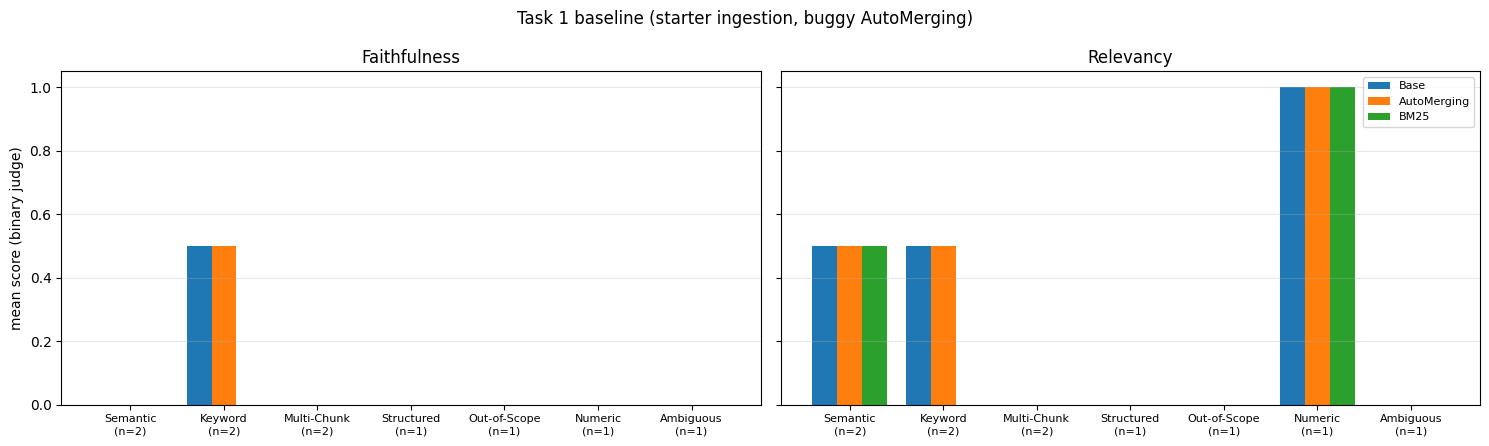

,category,retriever,question,expected,answer,refused,relevancy,faithfulness,pages
21,Out-of-Scope,Base,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,The provided text does not contain any specifi...,True,0.0,0.0,4
22,Out-of-Scope,AutoMerging,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,The provided text does not contain any specifi...,True,0.0,0.0,4
23,Out-of-Scope,BM25,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,"Unfortunately, the provided text does not cont...",True,0.0,0.0,4
24,Numeric,Base,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,"According to the given context, about 30% of p...",False,1.0,0.0,"3,6"
25,Numeric,AutoMerging,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,"According to the given context, about 30% of p...",False,1.0,0.0,"3,6"
26,Numeric,BM25,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,30%,False,1.0,0.0,6
27,Ambiguous,Base,"Both of my parents had migraines, so am I cert...",The report does not say. It does not discuss g...,"Based on the provided context, having both par...",False,0.0,0.0,"6,8,9"
28,Ambiguous,AutoMerging,"Both of my parents had migraines, so am I cert...",The report does not say. It does not discuss g...,"Based on the provided context, having both par...",False,0.0,0.0,"6,8,9"
29,Ambiguous,BM25,"Both of my parents had migraines, so am I cert...",The report does not say. It does not discuss g...,"Based on the provided context, there is no dir...",False,0.0,0.0,"8,9"


In [ ]:
t1_base = run_answer_eval(engines_from(starter_suite, ["Base", "AutoMerging", "BM25"]), qdf, tag="t1_baseline_buggy")
overall, by_cat = summarize_answers(t1_base)
display(overall); display(by_cat)
plot_by_category(t1_base, "Task 1 baseline (starter ingestion, buggy AutoMerging)", "t1_baseline_by_category.png")
display(manual_check_table(t1_base))

### 🐞 Bug hunt: the starter's AutoMerging retriever never merges

**What's wrong.** `AutoMergingRetriever` only does something when the retrieved nodes are *children* that share a *parent*:
if more than `simple_ratio_thresh` (0.5) of a parent's children are retrieved, they are swapped for the parent. The starter builds
its index from **flat** `SentenceSplitter` chunks, so no node has a parent relationship. The retriever therefore runs without errors but
returns the same chunks as a plain top-3 vector search (at most it "fills in" a single adjacent chunk). It is just vector search with
a different k under another name.

**Fix.**
1. Parse with `HierarchicalNodeParser` (e.g. sizes `[1024, 512, 256]`), which creates parent/child relationships.
2. Put **all** nodes (parents and leaves) in the docstore, because the retriever looks parents up there.
3. Build the vector index on the **leaf nodes only**, retrieve leaves with the same `TOP_K`, and wrap that in `AutoMergingRetriever`.

The cells below provide the evidence: (a) the starter nodes have zero parents and zero merges occur; (b) the fixed version merges on real
queries and returns parent nodes that are larger than its leaves.

In [ ]:
def merge_stats(retriever, leaf_ids, questions):
    rows = []
    for q in questions:
        res = retriever.retrieve(q)
        merged = [n for n in res if n.node.node_id not in leaf_ids]      # anything not a leaf = a merged parent
        rows.append(dict(question=q[:60], returned=len(res), merged_parents=len(merged),
                         avg_chars=int(np.mean([len(n.node.get_content()) for n in res])) if res else 0))
    return pd.DataFrame(rows)

probe_qs = list(qdf.question) + [qa for qa in ["What is chronic migraine?", "How is migraine treated?", "What triggers migraines?"]]

# (a) BUGGY starter version
print("Starter nodes with a parent:", sum(n.parent_node is not None for n in starter_nodes), "of", len(starter_nodes))
buggy = merge_stats(starter_suite["AutoMerging"], {n.node_id for n in starter_nodes}, probe_qs)
same_as_vector = np.mean([[n.node.node_id for n in starter_suite["AutoMerging"].retrieve(q)] ==
                          [n.node.node_id for n in starter_suite["Base"].retrieve(q)] for q in probe_qs])
print(f"BUGGY: merges = {buggy.merged_parents.sum()} | identical to plain vector top-{TOP_K} on {same_as_vector:.0%} of queries")

# (b) FIXED version on the same starter documents (leaf = 256 to match the starter chunk size)
fixed_amr, fixed_all, fixed_leaves = make_automerging(starter_docs, leaf_size=256, k=TOP_K, verbose=True)
print(f"FIXED: {len(fixed_all)} nodes total, {len(fixed_leaves)} leaves, "
      f"{sum(n.parent_node is not None for n in fixed_all)} nodes with a parent")
fixed = merge_stats(fixed_amr, {n.node_id for n in fixed_leaves}, probe_qs)
print(f"FIXED: queries with >=1 merge: {(fixed.merged_parents > 0).sum()}/{len(fixed)} | "
      f"avg returned chars {fixed.avg_chars.mean():.0f} vs buggy {buggy.avg_chars.mean():.0f}")
display(fixed)

Starter nodes with a parent: 0 of 75
BUGGY: merges = 0 | identical to plain vector top-3 on 100% of queries
FIXED: 137 nodes total, 83 leaves, 119 nodes with a parent
> Merging 2 nodes into parent node.
> Parent node id: 394402c7-4584-4d08-ba90-bf3ec7fcf8ae.
> Parent node text: Another benefit of prevention, says Dominguez, 
is that “a really good preventive treatment strat...

> Merging 1 nodes into parent node.
> Parent node id: 40dc0a05-99ec-4e42-a958-a88e060a095b.
> Parent node text: At the 
end of the day, two things have been the most helpful 
for me: prescription migraine medi...

> Merging 1 nodes into parent node.
> Parent node id: 40dc0a05-99ec-4e42-a958-a88e060a095b.
> Parent node text: At the 
end of the day, two things have been the most helpful 
for me: prescription migraine medi...

> Merging 2 nodes into parent node.
> Parent node id: 15e58fc2-bd0e-4fab-9d3f-279d85626282.
> Parent node text: “Immediate relief doesn’t happen that often in chronic 
migraine,” says Jorge L

,question,returned,merged_parents,avg_chars
0,"Besides taking medication, what other kinds of...",2,2,868
1,Could paying attention to my daily routine hel...,3,1,294
2,"What is CGRP, and which drugs does the report ...",2,1,911
3,How is eptinezumab (VYEPTI) given and how often?,2,1,893
4,"How long does a migraine attack last, and how ...",3,0,508
5,"What side effects does eptinezumab have, and w...",3,0,793
6,How long does the postdrome stage of a migrain...,3,1,460
7,How much does a VYEPTI infusion cost?,2,1,1184
8,What percentage of people with chronic migrain...,3,1,645
9,"Both of my parents had migraines, so am I cert...",3,1,679


> Merging 2 nodes into parent node.
> Parent node id: 394402c7-4584-4d08-ba90-bf3ec7fcf8ae.
> Parent node text: Another benefit of prevention, says Dominguez, 
is that “a really good preventive treatment strat...

> Merging 1 nodes into parent node.
> Parent node id: 40dc0a05-99ec-4e42-a958-a88e060a095b.
> Parent node text: At the 
end of the day, two things have been the most helpful 
for me: prescription migraine medi...

  ✓ Semantic     Besides taking medication, what other kinds of approaches might help s
> Merging 1 nodes into parent node.
> Parent node id: 40dc0a05-99ec-4e42-a958-a88e060a095b.
> Parent node text: At the 
end of the day, two things have been the most helpful 
for me: prescription migraine medi...

  ✓ Semantic     Could paying attention to my daily routine help me see a migraine atta
> Merging 2 nodes into parent node.
> Parent node id: 15e58fc2-bd0e-4fab-9d3f-279d85626282.
> Parent node text: “Immediate relief doesn’t happen that often in chronic 
migraine,” say

,faithfulness,relevancy
retriever,,
AutoMerging,0.0,0.1
BM25,0.0,0.2
Base,0.1,0.3


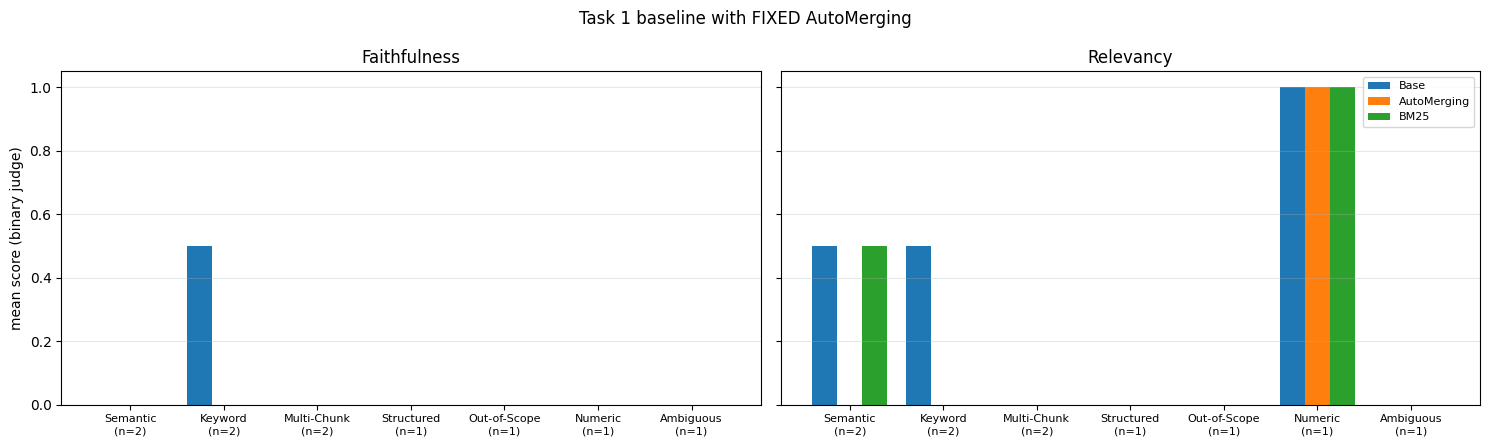

,category,retriever,question,expected,answer,refused,relevancy,faithfulness,pages
21,Out-of-Scope,Base,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,The provided text does not contain any specifi...,True,0.0,0.0,4
22,Out-of-Scope,AutoMerging,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,The provided text does not contain specific pr...,True,0.0,0.0,4
23,Out-of-Scope,BM25,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,"Unfortunately, the provided text does not cont...",True,0.0,0.0,4
24,Numeric,Base,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,"According to the given context, about 30% of p...",False,1.0,0.0,"3,6"
25,Numeric,AutoMerging,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,30%,False,1.0,0.0,"6,9"
26,Numeric,BM25,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,30%,False,1.0,0.0,6
27,Ambiguous,Base,"Both of my parents had migraines, so am I cert...",The report does not say. It does not discuss g...,"Based on the provided context, having both par...",False,0.0,0.0,"6,8,9"
28,Ambiguous,AutoMerging,"Both of my parents had migraines, so am I cert...",The report does not say. It does not discuss g...,"Based on the provided context, having both of ...",False,0.0,0.0,"6,8,9"
29,Ambiguous,BM25,"Both of my parents had migraines, so am I cert...",The report does not say. It does not discuss g...,"Based on the provided context, there is no dir...",False,0.0,0.0,"8,9"


In [ ]:
# Baseline re-run with the FIXED AutoMerging (same starter ingestion, same k); used from here on.
starter_suite_fixed = dict(starter_suite, AutoMerging=fixed_amr)
t1_fixed = run_answer_eval(engines_from(starter_suite_fixed, ["Base", "AutoMerging", "BM25"]), qdf, tag="t1_baseline_fixed")
display(summarize_answers(t1_fixed)[0])
plot_by_category(t1_fixed, "Task 1 baseline with FIXED AutoMerging", "t1_fixed_by_category.png")
display(manual_check_table(t1_fixed))

---
# Task 2 · Optimizing the Ingestion Pipeline
Retrieval metrics only, **vector (base) retriever only**, on one synthetic dataset.

### 2.0 Document structure analysis & structure-aware loader

In [ ]:
import pdfplumber
with pdfplumber.open(PDF_PATH) as pdf:
    print(f"{len(pdf.pages)} pages")
    for i, p in enumerate(pdf.pages, 1):
        words = p.extract_words()
        g = _find_gutter(p, words, .08 * p.height, .94 * p.height)
        print(f"p{i:2d}: {len(words):4d} words | tables={len(p.find_tables())} | images={len(p.images)} | "
              f"layout={'2-column (gutter x=%.0f)' % g if g else '1-column'}")

# What the default reader produces (look for: headings as symbol soup, columns interleaved, "(cid:..)" glyphs)
for d in starter_docs[:9]:
    t = d.text
    garbled = sum(1 for l in t.splitlines() if l.strip() and clean_line(l) is None)
    print(f"--- default reader, page {d.metadata.get('page_label')}: {len(t)} chars, {garbled} garbled lines, "
          f"{t.count('(cid:')} broken glyphs ---")
print("\nExample (page 3):\n", starter_docs[2].text[:900])

9 pages
p 1:   56 words | tables=1 | images=2 | layout=2-column (gutter x=390)
p 2:  170 words | tables=1 | images=1 | layout=1-column
p 3:  357 words | tables=0 | images=1 | layout=1-column
p 4:  341 words | tables=0 | images=0 | layout=1-column
p 5:  159 words | tables=1 | images=1 | layout=1-column
p 6:  288 words | tables=0 | images=10038 | layout=1-column
p 7:  577 words | tables=0 | images=0 | layout=2-column (gutter x=286)
p 8:  525 words | tables=0 | images=0 | layout=2-column (gutter x=288)
p 9:  125 words | tables=0 | images=2 | layout=1-column
--- default reader, page 1: 1734 chars, 0 garbled lines, 0 broken glyphs ---
--- default reader, page 2: 4075 chars, 0 garbled lines, 0 broken glyphs ---
--- default reader, page 3: 3864 chars, 0 garbled lines, 0 broken glyphs ---
--- default reader, page 4: 2528 chars, 0 garbled lines, 0 broken glyphs ---
--- default reader, page 5: 1241 chars, 0 garbled lines, 0 broken glyphs ---
--- default reader, page 6: 2920 chars, 0 garbled line

In [ ]:
def load_structured_documents(pdf_path, table_mode="separate", mode="flow"):
    # table_mode: 'separate' = one Document per table | 'inline' = table appended to its page | 'none' = drop tables
    # mode: 'flow' = text-flow reading order (frames) | 'columns' = geometric left/right gutter split
    pages, tables = extract_pdf_structured(pdf_path, mode=mode)
    fname = os.path.basename(pdf_path)
    tables_by_page = {}
    for t in tables: tables_by_page.setdefault(t["page"], []).append(t["text"])
    docs = []
    for p in pages:
        text = "\n\n".join(p["paragraphs"])                     # paragraphs separated by blank lines
        if table_mode == "inline" and p["page"] in tables_by_page:
            text += "\n\n" + "\n\n".join(tables_by_page[p["page"]])
        if text.strip():
            docs.append(Document(text=text, metadata={"page_label": str(p["page"]), "file_name": fname}))
    if table_mode == "separate":
        for t in tables:
            docs.append(Document(text=t["text"], metadata={"page_label": str(t["page"]), "file_name": fname, "content_type": "table"}))
    for d in docs:   # keep metadata out of the token budget of tiny chunks (avoids metadata-length warnings)
        d.excluded_embed_metadata_keys = ["file_name", "content_type"]
        d.excluded_llm_metadata_keys = ["file_name", "content_type"]
    return docs

clean_docs = load_structured_documents(PDF_PATH, "separate")
print(f"{len(clean_docs)} documents ({sum(d.metadata.get('content_type')=='table' for d in clean_docs)} tables)")
print(clean_docs[0].text[:700])

10 documents (1 tables)
CHRONIC MIGRAINE

COMPLIMENTARY COPY

TAKE ONE HOME

SCAN ME Watch this video on one woman’s journey living with chronic migraine. For more on her story, turn to page 14. Use your smartphone camera to activate the QR code.


### 2.1 Synthetic retrieval dataset (generated once, cached)
Generated from a **neutral reference chunking** of the cleaned text (`chunk_size=200, overlap=0`, a size that is *not* in the sweep, so no
configuration gets an "identical boundaries" advantage). Junk lines produced by the generator (headers, too-short strings) are filtered out.

In [ ]:
QA_PATH = f"{RESULTS_DIR}/qa_dataset_{LLM_BACKEND}.json"
ref_nodes = SentenceSplitter(chunk_size=200, chunk_overlap=0).get_nodes_from_documents(clean_docs)
if os.path.exists(QA_PATH) and not FORCE_RERUN:
    qa_dataset = EmbeddingQAFinetuneDataset.from_json(QA_PATH)
else:
    raw = generate_question_context_pairs(nodes=ref_nodes, llm=llm, num_questions_per_chunk=3)  # short report -> 3 per chunk
    keep = {k: v.strip() for k, v in raw.queries.items()
            if len(v.split()) >= 4 and "?" in v and not re.search(r"(here are|questions?:|context information)", v, re.I)}
    qa_dataset = EmbeddingQAFinetuneDataset(queries=keep, corpus=raw.corpus,
                                            relevant_docs={k: raw.relevant_docs[k] for k in keep})
    qa_dataset.save_json(QA_PATH)
print(f"{len(qa_dataset.queries)} synthetic questions over {len(ref_nodes)} reference chunks")
for q in list(qa_dataset.queries.values())[:8]: print(" ·", q)

100%|██████████| 25/25 [01:06<00:00,  2.67s/it]

62 synthetic questions over 25 reference chunks
 · **What is the main focus of the promotional material mentioned at the beginning?**
 · **According to the text, what does the woman's story reveal about her experience with chronic migraine?**
 · What is the purpose of WebMD Real Stories?
 · Who publishes WebMD Real Stories?
 · How can one obtain permission to reproduce the content from WebMD Real Stories?
 · What factors contribute to the development of weather-related migraines?
 · How does the research suggest that individuals living with chronic migraines can prepare themselves better through weather forecasts?
 · In what ways do people with chronic migraines feel stigmatized, and how might this impact their quality of life?


In [ ]:
# Validation of the content-overlap metric: on the reference ingestion (where node ids DO match) it should agree
# closely with LlamaIndex's official id-based RetrieverEvaluator.
ref_index = VectorStoreIndex(IngestionPipeline(transformations=[embed_model]).run(nodes=ref_nodes))
ref_ret = ref_index.as_retriever(similarity_top_k=TOP_K)
try:
  official = asyncio.run(RetrieverEvaluator.from_metric_names(["hit_rate", "mrr", "precision", "recall"],
                                                            retriever=ref_ret).aevaluate_dataset(qa_dataset))
  official_mean = pd.DataFrame([r.metric_vals_dict for r in official]).mean()
  ours = retrieval_metrics(ref_ret, qa_dataset, "reference (overlap metric)")
  display(pd.DataFrame({"official id-based": official_mean, "content-overlap": pd.Series(ours)[["hit_rate","mrr","precision","recall"]]}).round(3))
except Exception as e:
  print("Validation skipped (optional):", type(e).__name__, e)

,official id-based,content-overlap
hit_rate,0.935,0.935484
mrr,0.841,0.841398
precision,0.312,0.311828
recall,0.935,0.936008


### 2.2 Chunk-size ablation (`chunk_overlap = 32` fixed, vector retriever)

,retriever,hit_rate,mrr,precision,recall,ms_per_query,n_queries,node_count
chunk_size,,,,,,,,
64,chunk=64,0.903,0.745,0.505,0.518,9.868,62,107
128,chunk=128,0.887,0.798,0.419,0.711,8.263,62,43
256,chunk=256,0.871,0.715,0.306,0.880,7.972,62,20
512,chunk=512,0.871,0.790,0.323,0.863,10.898,62,13


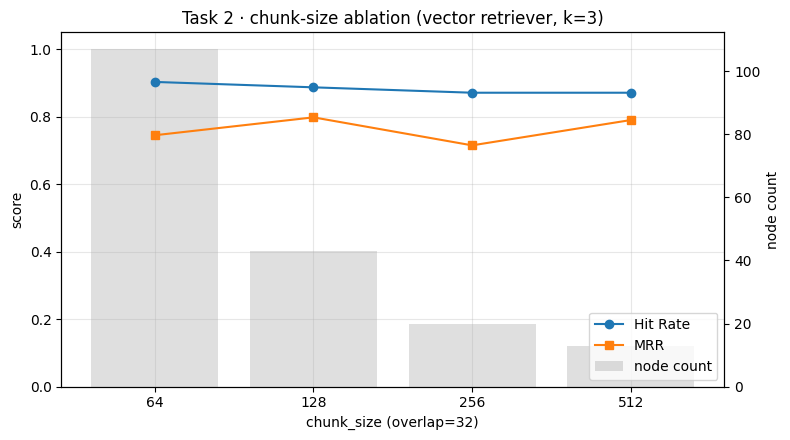

Chosen chunk size: 128


In [ ]:
ablation = []
for cs in [64, 128, 256, 512]:
    nodes = make_nodes(clean_docs, cs, 32)
    m = retrieval_metrics(VectorStoreIndex(nodes).as_retriever(similarity_top_k=TOP_K), qa_dataset, f"chunk={cs}")
    m.update(chunk_size=cs, node_count=len(nodes)); ablation.append(m)
abl_df = pd.DataFrame(ablation).set_index("chunk_size").round(3)
display(abl_df)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(abl_df))
ax2 = ax1.twinx()
ax2.bar(x, abl_df.node_count, alpha=.25, color="gray", label="node count"); ax2.set_ylabel("node count")
ax1.plot(x, abl_df.hit_rate, "o-", label="Hit Rate"); ax1.plot(x, abl_df.mrr, "s-", label="MRR")
ax1.set_zorder(ax2.get_zorder() + 1); ax1.patch.set_visible(False)
ax1.set_xticks(x); ax1.set_xticklabels(abl_df.index); ax1.set_xlabel("chunk_size (overlap=32)")
ax1.set_ylim(0, 1.05); ax1.set_ylabel("score"); ax1.grid(alpha=.3)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax1.legend(h1 + h2, l1 + l2, loc="lower right")
plt.title("Task 2 · chunk-size ablation (vector retriever, k=3)"); plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/t2_chunk_ablation.png", dpi=150); plt.show()

BEST_CS = int(abl_df.sort_values(["mrr", "hit_rate"], ascending=False).index[0])   # override by hand if you prefer
print("Chosen chunk size:", BEST_CS)

### 2.3 Pipeline refinement at the chosen chunk size
One factor at a time (greedy): **loader** → **overlap** → **splitting unit** (sentence vs. paragraph-first) → **table handling**. Each step keeps the best value of the previous one.

In [ ]:
def eval_cfg(docs, cs, ov, sep, label):
    nodes = make_nodes(docs, cs, ov, sep)
    m = retrieval_metrics(VectorStoreIndex(nodes).as_retriever(similarity_top_k=TOP_K), qa_dataset, label)
    m["node_count"] = len(nodes); return m

SENT, PARA = "\n\n\n", "\n\n"   # SENT = SentenceSplitter default; PARA = prefer our blank-line paragraph breaks
docs_by_table = {m: load_structured_documents(PDF_PATH, m) for m in ["separate", "inline", "none"]}
runs = []
# (a) loader: default reader vs structure-aware loader at the same settings
# copies of the starter docs with their long default metadata (path, size, dates) excluded, so tiny chunks don't fail
starter_docs_lean = [Document(text=d.text, metadata={"page_label": d.metadata.get("page_label", "?")}) for d in starter_docs]
runs.append(eval_cfg(starter_docs_lean, BEST_CS, 32, SENT, "loader=SimpleDirectoryReader+tabula"))
runs.append(eval_cfg(load_structured_documents(PDF_PATH, "separate", mode="columns"), BEST_CS, 32, SENT, "loader=pdfplumber(gutter columns)"))
runs.append(eval_cfg(clean_docs,   BEST_CS, 32, SENT, "loader=pdfplumber(text-flow + cleaning)"))
# (b) overlap
ov_runs = [eval_cfg(clean_docs, BEST_CS, ov, SENT, f"overlap={ov}") for ov in sorted({0, 32, 64, BEST_CS // 4}) if ov < BEST_CS // 2]
runs += ov_runs; BEST_OV = int(max(ov_runs, key=lambda m: (m["mrr"], m["hit_rate"]))["retriever"].split("=")[1])
# (c) splitting unit
sp_runs = [eval_cfg(clean_docs, BEST_CS, BEST_OV, s, f"split={n}") for n, s in [("sentence", SENT), ("paragraph-first", PARA)]]
runs += sp_runs; BEST_SEP = PARA if max(sp_runs, key=lambda m: (m["mrr"], m["hit_rate"]))["retriever"].endswith("first") else SENT
# (d) table handling
tb_runs = [eval_cfg(docs_by_table[t], BEST_CS, BEST_OV, BEST_SEP, f"tables={t}") for t in ["separate", "inline", "none"]]
runs += tb_runs; BEST_TABLES = max(tb_runs, key=lambda m: (m["mrr"], m["hit_rate"]))["retriever"].split("=")[1]

refine_df = metrics_df(runs); display(refine_df)
FINAL_CFG = dict(chunk_size=BEST_CS, chunk_overlap=BEST_OV, paragraph_separator=BEST_SEP)
final_text_docs = docs_by_table[BEST_TABLES]
print("Optimized ingestion:", FINAL_CFG, "| tables:", BEST_TABLES)

,hit_rate,mrr,precision,recall,ms_per_query,n_queries,node_count
retriever,,,,,,,
loader=SimpleDirectoryReader+tabula,0.806,0.704,0.333,0.517,12.410,62,204
loader=pdfplumber(gutter columns),0.661,0.548,0.285,0.516,8.542,62,40
loader=pdfplumber(text-flow + cleaning),0.887,0.798,0.419,0.711,8.593,62,43
overlap=0,0.855,0.726,0.371,0.716,8.309,62,36
overlap=32,0.887,0.798,0.419,0.711,8.554,62,43
split=sentence,0.887,0.798,0.419,0.711,8.569,62,43
split=paragraph-first,0.887,0.750,0.382,0.683,8.616,62,42
tables=separate,0.887,0.798,0.419,0.711,8.998,62,43
tables=inline,0.871,0.785,0.425,0.722,9.276,62,42


Optimized ingestion: {'chunk_size': 128, 'chunk_overlap': 32, 'paragraph_separator': '\n\n\n'} | tables: separate


,hit_rate,mrr,precision,recall,ms_per_query,n_queries
retriever,,,,,,
"Starter (reader+tabula, 256/0)",0.774,0.699,0.269,0.637,14.308,62
"Optimized (128/32, separate tables)",0.887,0.798,0.419,0.711,8.337,62


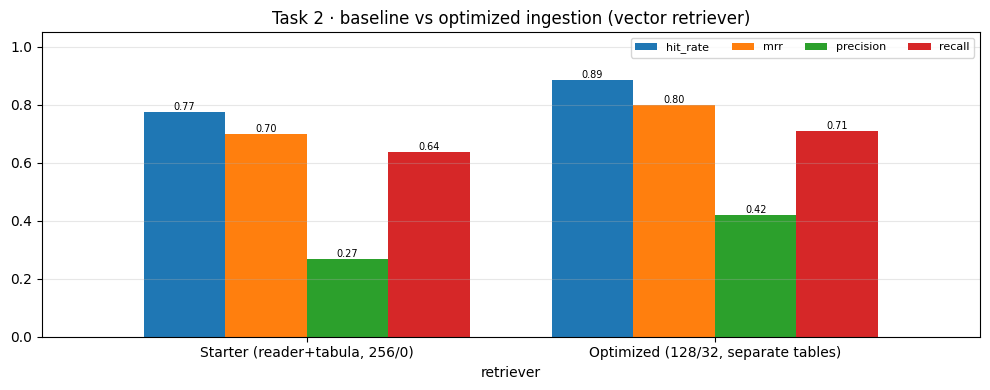

In [ ]:
# 2.4 Starter baseline ingestion vs fully optimized ingestion (vector retriever, k=3)
t2_cmp = metrics_df([
    retrieval_metrics(starter_index.as_retriever(similarity_top_k=TOP_K), qa_dataset, "Starter (reader+tabula, 256/0)"),
    retrieval_metrics(VectorStoreIndex(make_nodes(final_text_docs, **FINAL_CFG)).as_retriever(similarity_top_k=TOP_K),
                      qa_dataset, f"Optimized ({BEST_CS}/{BEST_OV}, {BEST_TABLES} tables)"),
])
display(t2_cmp)
bar_metrics(t2_cmp, "Task 2 · baseline vs optimized ingestion (vector retriever)", "t2_baseline_vs_optimized.png")

---
# Task 3 · Extracting Information from Images
* **Image mode:** every embedded raster image (PyMuPDF), skipping icons/logos (small or repeated), upscaled and grayscaled for Tesseract.
* **Page fallback:** charts/infographics drawn as vector graphics are not "images", so pages are also rendered at 300 dpi and OCR'd, keeping
  **only lines that are not already in the text layer** (no duplicate noise).
* Text from all images on a page is aggregated into one `Document` per page with `page_label` (so answers can cite pages); the single
  combined document is also built for inspection.

In [ ]:
import fitz, pytesseract
from PIL import Image, ImageOps

def _clean_ocr(text):
    keep = []
    for line in text.splitlines():
        line = re.sub(r"\s+", " ", line).strip()
        if len(line) < 3: continue
        alnum = sum(c.isalnum() for c in line) / len(line)
        if alnum >= 0.6 and re.search(r"[A-Za-z]{2,}", line):   # drop OCR garbage lines
            keep.append(line)
    return "\n".join(keep)

def _prep(img):
    img = ImageOps.grayscale(img.convert("RGB"))
    if img.width < 1200: img = img.resize((img.width * 2, img.height * 2), Image.LANCZOS)
    return ImageOps.autocontrast(img)

def ocr_document_images(pdf_path, min_side=120, page_fallback=True):
    doc = fitz.open(pdf_path)
    page_texts, seen_xref, seen_text = {}, set(), set()
    for pno, page in enumerate(doc, start=1):
        # (1) embedded raster images
        for info in page.get_images(full=True):
            xref = info[0]
            if xref in seen_xref: continue                     # same logo on every page
            seen_xref.add(xref)
            pix = fitz.Pixmap(doc, xref)
            if pix.width < min_side or pix.height < min_side: continue
            if pix.n - pix.alpha >= 4: pix = fitz.Pixmap(fitz.csRGB, pix)
            txt = _clean_ocr(pytesseract.image_to_string(_prep(Image.open(io.BytesIO(pix.tobytes("png")))), config="--oem 3 --psm 3"))
            if len(txt) > 20 and txt not in seen_text:
                seen_text.add(txt); page_texts.setdefault(pno, []).append(txt)
        # (2) rendered page: keep only text that the text layer does NOT already contain
        if page_fallback:
            layer = shingles(page.get_text())
            pix = page.get_pixmap(dpi=300)
            full = _clean_ocr(pytesseract.image_to_string(Image.open(io.BytesIO(pix.tobytes("png"))), config="--oem 3 --psm 3"))
            novel = [l for l in full.splitlines()
                     if (len(l.split()) >= 2 or len(l) >= 5) and overlap_coef(shingles(l), layer, floor=1) < 0.5]
            novel = [l for l in novel if not any(l in t for t in page_texts.get(pno, []))]
            if len(" ".join(novel)) > 20: page_texts.setdefault(pno, []).append("\n".join(novel))
    ocr_docs = [Document(text=f"[Text extracted by OCR from images/figures on page {p}]\n" + "\n\n".join(ts),
                         metadata={"page_label": str(p), "source": "ocr", "file_name": os.path.basename(pdf_path)},
                         excluded_embed_metadata_keys=["file_name", "source"], excluded_llm_metadata_keys=["file_name", "source"])
                for p, ts in sorted(page_texts.items())]
    combined = Document(text="\n\n".join(d.text for d in ocr_docs), metadata={"source": "ocr_combined"})
    return ocr_docs, combined

try:
    pytesseract.get_tesseract_version()
    ocr_docs, ocr_combined = ocr_document_images(PDF_PATH)
except Exception as e:
    print("⚠️ OCR unavailable (re-run the install cell for tesseract):", e)
    ocr_docs, ocr_combined = [], Document(text="")
print(f"OCR: {len(ocr_docs)} page documents, {len(ocr_combined.text)} chars total")
for d in ocr_docs[:4]: print(f"\n--- p.{d.metadata['page_label']} ---\n{d.text[:500]}")

OCR: 8 page documents, 2992 chars total

--- p.1 ---
[Text extracted by OCR from images/figures on page 1]
EAL STO
A look inside
your head
and more
page 9
How |! help others
help me
page 14
_ Prioritize
COMPLIMENTARY COPY
SCAN ME?
WINTER 2025

--- p.2 ---
[Text extracted by OCR from images/figures on page 2]
WebMD | cHRONIC MIGRAINE CONTENTS
_ Manage your chroni
he ri
Bei iy ie
The latest research Being my own advocate
HEALTH SMARTS VIEWPOINT
A look inside your head Here’s how | help others help me
and more through chronic migraine
TREATMENT SMARTS LIVING HEALTHY
INSIDE THE ISSUE
FIRST PERSON
c migraine Prioritize lifestyle changes
7 te
GETTY IMAGES

--- p.3 ---
[Text extracted by OCR from images/figures on page 3]
NEWS CHRONIC MIGRAINE | WebMD
THE LATEST ON
-CHRONIC MIGRAINE
PREVENTION IN
YOUR POCKET
who had more stress or significantly higher-than-usual energy FIND S U Pp PO RT FO R STI G MA
SOURCE: Neurology
CLOUDY WITH A CHANCE OF ...
MIGRAINE?
weather forecast.

--- p.4 ---
[Text 

In [ ]:
final_docs = final_text_docs + ocr_docs        # Task 2 optimized text + OCR documents
suite_no_ocr = build_suite(final_text_docs, **FINAL_CFG, kinds=("Base", "AutoMerging", "BM25"))
suite_ocr    = build_suite(final_docs,      **FINAL_CFG, kinds=("Base", "AutoMerging", "BM25"))

t3_no = run_answer_eval(engines_from(suite_no_ocr, ["Base", "AutoMerging", "BM25"]), qdf, "t3_without_ocr")
t3_yes = run_answer_eval(engines_from(suite_ocr,   ["Base", "AutoMerging", "BM25"]), qdf, "t3_with_ocr")
t3 = pd.concat([t3_no.assign(ocr="without"), t3_yes.assign(ocr="with")])
display(t3.groupby(["ocr", "retriever"])[["faithfulness", "relevancy"]].mean().unstack(0).round(3))

# "Did OCR hurt anything else?": same table restricted to the NON-image questions
display(t3[t3.category != "Structured"].groupby(["ocr", "retriever"])[["faithfulness", "relevancy"]].mean().unstack(0).round(3))

DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects


  ✓ Semantic     Besides taking medication, what other kinds of approaches might help s
  ✓ Semantic     Could paying attention to my daily routine help me see a migraine atta
  ✓ Keyword      What is CGRP, and which drugs does the report say block it?
  ✓ Keyword      How is eptinezumab (VYEPTI) given and how often?
  ✓ Multi-Chunk  How long does a migraine attack last, and how does that compare with c
  ✓ Multi-Chunk  What side effects does eptinezumab have, and what can a patient do if 
  ✓ Structured   How long does the postdrome stage of a migraine last?
  ✓ Out-of-Scope How much does a VYEPTI infusion cost?
  ✓ Numeric      What percentage of people with chronic migraine also have fibromyalgia
  ✓ Ambiguous    Both of my parents had migraines, so am I certain to get chronic migra
  ✓ Semantic     Besides taking medication, what other kinds of approaches might help s
  ✓ Semantic     Could paying attention to my daily routine help me see a migraine atta
  ✓ Keyword      What is CG

faithfulness         relevancy        
ocr                 with without      with without
retriever                                         
AutoMerging          0.0     0.1       0.1     0.0
BM25                 0.0     0.0       0.1     0.1
Base                 0.2     0.0       0.0     0.0

faithfulness         relevancy        
ocr                 with without      with without
retriever                                         
AutoMerging        0.000   0.111     0.111   0.000
BM25               0.000   0.000     0.111   0.111
Base               0.222   0.000     0.000   0.000

In [ ]:
# Before / after example: the image-based (Structured) question
cols = ["ocr", "retriever", "question", "expected", "answer", "faithfulness", "relevancy", "pages"]
display(t3[t3.category == "Structured"].sort_values(["retriever", "ocr"], ascending=[True, False])[cols])
# Retrieval-level evidence: does an OCR chunk now appear in the top-k?
for q in qdf[qdf.category == "Structured"].question:
    for name in ["Base", "BM25"]:
        res = suite_ocr[name].retrieve(q)
        print(name, "→", [("OCR" if n.node.metadata.get("source") == "ocr" else "text") + f"(p.{n.node.metadata.get('page_label')})" for n in res])

,ocr,retriever,question,expected,answer,faithfulness,relevancy,pages
19,without,AutoMerging,How long does the postdrome stage of a migrain...,24 to 48 hours. This is only in the Migraine S...,The postdrome stage of a migraine typically la...,0.0,0.0,"3,8"
19,with,AutoMerging,How long does the postdrome stage of a migrain...,24 to 48 hours. This is only in the Migraine S...,The postdrome stage of a migraine lasts from 2...,0.0,0.0,"3,5,8"
20,without,BM25,How long does the postdrome stage of a migrain...,24 to 48 hours. This is only in the Migraine S...,The postdrome stage of a migraine typically la...,0.0,0.0,"3,8"
20,with,BM25,How long does the postdrome stage of a migrain...,24 to 48 hours. This is only in the Migraine S...,The postdrome stage of a migraine typically la...,0.0,0.0,"3,5"
18,without,Base,How long does the postdrome stage of a migrain...,24 to 48 hours. This is only in the Migraine S...,The postdrome stage of a migraine typically la...,0.0,0.0,"3,7"
18,with,Base,How long does the postdrome stage of a migrain...,24 to 48 hours. This is only in the Migraine S...,The postdrome stage of a migraine typically la...,0.0,0.0,"3,5,7"


Base → ['OCR(p.5)', 'text(p.3)', 'text(p.7)']
BM25 → ['text(p.3)', 'OCR(p.5)', 'text(p.3)']


---
# Task 4 · Hybrid Retrieval
`QueryFusionRetriever` over a vector retriever and a BM25 retriever (each `FUSION_CAND_K = 10`), `mode="relative_score"`,
`retriever_weights=[0.6, 0.4]`, `num_queries=1` (no LLM query rewriting), final `similarity_top_k = TOP_K = 3`, same as every other retriever.
Built on the final ingestion (optimized text + OCR).

In [ ]:
suite_final = build_suite(final_docs, **FINAL_CFG)      # Base, AutoMerging (fixed), BM25, Hybrid on the same ingestion
t4_ret = metrics_df([retrieval_metrics(suite_final[n], qa_dataset, n) for n in ["Base", "AutoMerging", "BM25", "Hybrid"]])
display(t4_ret)

# Hybrid design sweep (retrieval only: cheap, no LLM calls)
sweep = []
for w in [(0.8, 0.2), (0.7, 0.3), (0.6, 0.4), (0.5, 0.5), (0.4, 0.6)]:
    for mode in ["relative_score", "dist_based_score"]:
        r = make_hybrid(suite_final["_index"], suite_final["_nodes"], weights=w, mode=mode)
        sweep.append(retrieval_metrics(r, qa_dataset, f"{mode} w={w}"))
sweep.append(retrieval_metrics(make_hybrid(suite_final["_index"], suite_final["_nodes"], mode="reciprocal_rerank"), qa_dataset, "reciprocal_rerank (unweighted)"))
sweep_df = metrics_df(sweep).sort_values("mrr", ascending=False); display(sweep_df)

DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects


,hit_rate,mrr,precision,recall,ms_per_query,n_queries
retriever,,,,,,
Base,0.855,0.755,0.376,0.650,8.619,62
AutoMerging,0.774,0.691,0.368,0.638,9.254,62
BM25,0.742,0.653,0.301,0.553,1.789,62
Hybrid,0.903,0.812,0.392,0.690,14.256,62


DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects


,hit_rate,mrr,precision,recall,ms_per_query,n_queries
retriever,,,,,,
"dist_based_score w=(0.7, 0.3)",0.887,0.825,0.392,0.687,11.867,62
"dist_based_score w=(0.6, 0.4)",0.887,0.825,0.382,0.670,11.809,62
"relative_score w=(0.6, 0.4)",0.903,0.812,0.392,0.690,11.464,62
"relative_score w=(0.5, 0.5)",0.903,0.812,0.382,0.681,12.742,62
"relative_score w=(0.7, 0.3)",0.887,0.806,0.392,0.679,12.023,62
"dist_based_score w=(0.8, 0.2)",0.887,0.804,0.403,0.696,11.716,62
"dist_based_score w=(0.5, 0.5)",0.887,0.801,0.371,0.663,12.217,62
reciprocal_rerank (unweighted),0.903,0.790,0.360,0.650,16.614,62
"relative_score w=(0.8, 0.2)",0.871,0.769,0.398,0.681,11.978,62


  ✓ Semantic     Besides taking medication, what other kinds of approaches might help s
  ✓ Semantic     Could paying attention to my daily routine help me see a migraine atta
  ✓ Keyword      What is CGRP, and which drugs does the report say block it?
  ✓ Keyword      How is eptinezumab (VYEPTI) given and how often?
  ✓ Multi-Chunk  How long does a migraine attack last, and how does that compare with c
  ✓ Multi-Chunk  What side effects does eptinezumab have, and what can a patient do if 
  ✓ Structured   How long does the postdrome stage of a migraine last?
  ✓ Out-of-Scope How much does a VYEPTI infusion cost?
  ✓ Numeric      What percentage of people with chronic migraine also have fibromyalgia
  ✓ Ambiguous    Both of my parents had migraines, so am I certain to get chronic migra


,faithfulness,relevancy
retriever,,
AutoMerging,0.0,0.1
BM25,0.0,0.1
Base,0.2,0.0
Hybrid,0.2,0.1


faithfulness                    relevancy                 
retriever     AutoMerging BM25 Base Hybrid AutoMerging BM25 Base Hybrid
category                                                               
Semantic              0.0  0.0  0.0    0.0         0.0  0.5  0.0    0.0
Keyword               0.0  0.0  0.5    0.5         0.5  0.0  0.0    0.0
Multi-Chunk           0.0  0.0  0.5    0.5         0.0  0.0  0.0    0.0
Structured            0.0  0.0  0.0    0.0         0.0  0.0  0.0    0.0
Out-of-Scope          0.0  0.0  0.0    0.0         0.0  0.0  0.0    0.0
Numeric               0.0  0.0  0.0    0.0         0.0  0.0  0.0    1.0
Ambiguous             0.0  0.0  0.0    0.0         0.0  0.0  0.0    0.0

,category,retriever,question,expected,answer,refused,relevancy,faithfulness,pages
28,Out-of-Scope,Base,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,The provided text does not contain any specifi...,True,0.0,0.0,4
29,Out-of-Scope,AutoMerging,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,The provided text does not contain any specifi...,True,0.0,0.0,4
30,Out-of-Scope,BM25,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,The provided context does not contain specific...,True,0.0,0.0,4
31,Out-of-Scope,Hybrid,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,The provided text does not contain any specifi...,True,0.0,0.0,4
32,Numeric,Base,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,About 30% of people with chronic migraine also...,False,0.0,0.0,6
33,Numeric,AutoMerging,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,About 30% of people with chronic migraine also...,False,0.0,0.0,6
34,Numeric,BM25,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,About 30% of people with chronic migraine also...,False,0.0,0.0,6
35,Numeric,Hybrid,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,About 30% of people with chronic migraine also...,False,1.0,0.0,6
36,Ambiguous,Base,"Both of my parents had migraines, so am I cert...",The report does not say. It does not discuss g...,"Based on the provided context, it seems unlike...",False,0.0,0.0,"6,8"
37,Ambiguous,AutoMerging,"Both of my parents had migraines, so am I cert...",The report does not say. It does not discuss g...,"Based on the provided context, it seems there'...",True,0.0,0.0,"6,8"


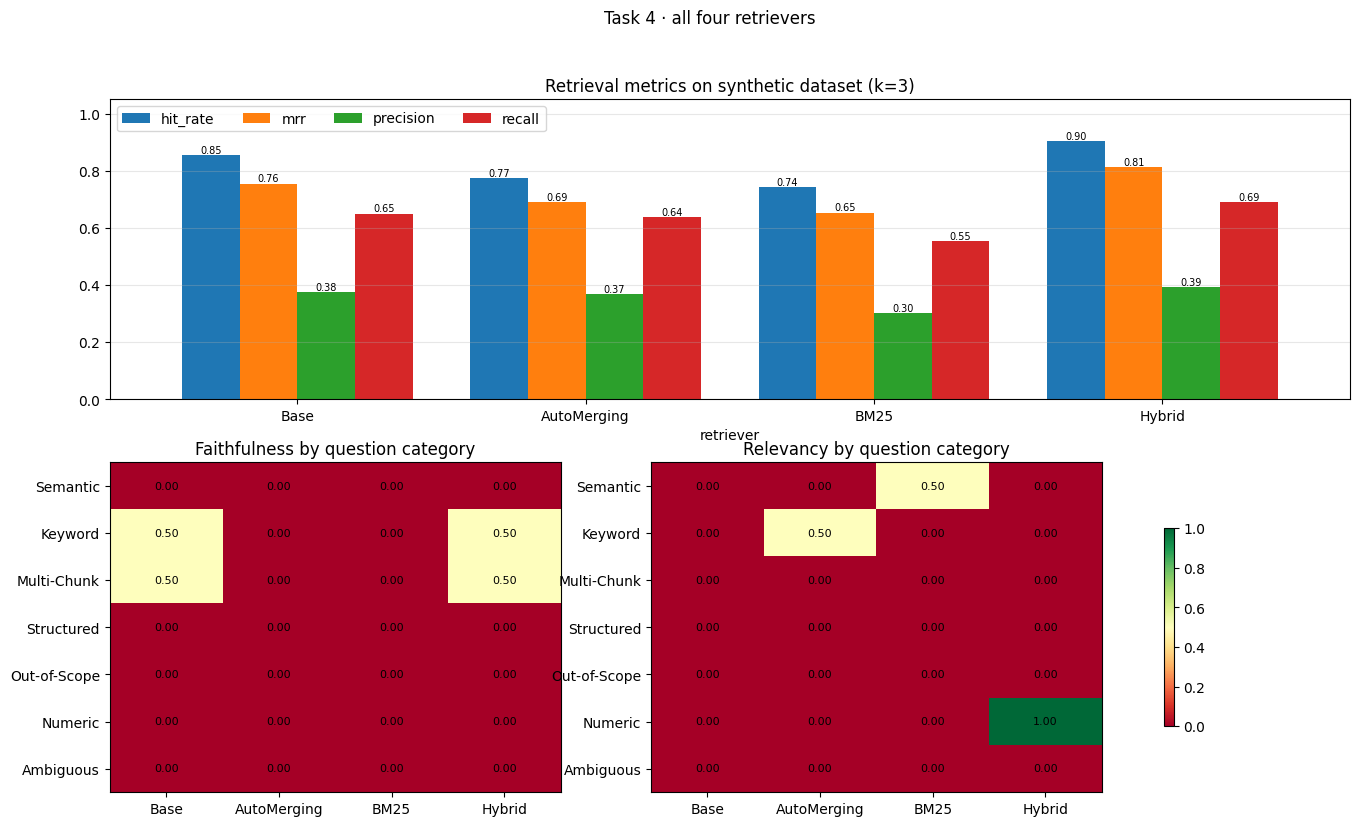

Best Task 4 retriever (by MRR): Hybrid


In [ ]:
t4_ans = run_answer_eval(engines_from(suite_final, ["Base", "AutoMerging", "BM25", "Hybrid"]), qdf, "t4_all_four")
display(summarize_answers(t4_ans)[0]); display(summarize_answers(t4_ans)[1])
display(manual_check_table(t4_ans))

# Summary figure: retrieval metrics + per-category heatmaps
fig = plt.figure(figsize=(16, 9)); gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])
ax = fig.add_subplot(gs[0, :])
t4_ret[["hit_rate", "mrr", "precision", "recall"]].plot.bar(ax=ax, rot=0, width=.8)
ax.set_ylim(0, 1.05); ax.set_title("Retrieval metrics on synthetic dataset (k=3)"); ax.grid(axis="y", alpha=.3); ax.legend(ncol=4)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
_, bc = summarize_answers(t4_ans)
for j, metric in enumerate(["faithfulness", "relevancy"]):
    a = fig.add_subplot(gs[1, j]); mat = bc[metric][["Base", "AutoMerging", "BM25", "Hybrid"]]
    im = a.imshow(mat.values, vmin=0, vmax=1, cmap="RdYlGn", aspect="auto")
    a.set_xticks(range(4)); a.set_xticklabels(mat.columns); a.set_yticks(range(len(mat))); a.set_yticklabels(mat.index)
    for (r, c), v in np.ndenumerate(mat.values): a.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8)
    a.set_title(f"{metric.capitalize()} by question category")
fig.colorbar(im, ax=fig.axes[1:], shrink=.6); fig.suptitle("Task 4 · all four retrievers")
plt.savefig(f"{RESULTS_DIR}/t4_summary.png", dpi=150, bbox_inches="tight"); plt.show()

BEST_T4 = t4_ret.sort_values(["mrr", "hit_rate"], ascending=False).index[0]
print("Best Task 4 retriever (by MRR):", BEST_T4)

---
# Task 5 · Making the RAG Better
Each improvement is applied **alone** on top of the best Task 4 setup and compared against it with the metrics it targets.

| # | Improvement | Targets | Listed in HW? |
|---|---|---|---|
| A | Cross-encoder re-ranking (retrieve 10 → rerank → top 3) | retrieval precision / MRR | yes (#1) |
| B | **HyDE on the vector branch of the hybrid**: embed an LLM-written hypothetical passage instead of the short question | semantic recall, vocabulary mismatch | **novel** |
| C | **Grounded, refusal-aware answer prompt with page citations** | out-of-scope hallucination, numeric precision, over-extrapolation | **novel** |

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects
DEBUG:bm25s:Building index from IDs objects


,hit_rate,mrr,precision,recall,ms_per_query,n_queries
retriever,,,,,,
Best T4 (Hybrid),0.903,0.812,0.392,0.690,13.112,62
A: + rerank,0.935,0.860,0.414,0.713,35.742,62
B: + HyDE,0.839,0.755,0.382,0.668,2626.085,62


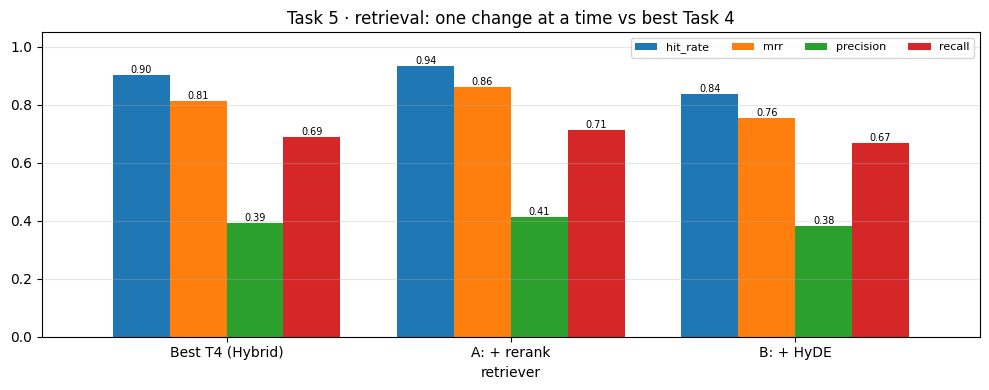

In [ ]:
from llama_index.core.postprocessor import SentenceTransformerRerank

def make_best(k=TOP_K, vector_retriever=None):
    # Rebuild the best Task-4 retriever type on the final ingestion with a given k.
    idx, nodes = suite_final["_index"], suite_final["_nodes"]
    if BEST_T4 == "Hybrid":  return make_hybrid(idx, nodes, k=k, vector_retriever=vector_retriever)
    if BEST_T4 == "BM25":    return make_bm25(nodes, k)
    if BEST_T4 == "AutoMerging": return make_automerging(final_docs, FINAL_CFG["chunk_size"], FINAL_CFG["chunk_overlap"], k=k)[0]
    return vector_retriever or idx.as_retriever(similarity_top_k=k)

class RerankRetriever(BaseRetriever):
    # Stage 1: best retriever with a large k. Stage 2: cross-encoder scores (query, passage) jointly.
    def __init__(self, first_stage, reranker):
        self.first_stage, self.reranker = first_stage, reranker; super().__init__()
    def _retrieve(self, qb):
        return self.reranker.postprocess_nodes(self.first_stage.retrieve(qb), query_bundle=qb)

class HyDEVectorRetriever(BaseRetriever):
    # Embeds mean(embedding(question), embedding(hypothetical answer passage)). BM25 still sees the raw question.
    PROMPT = ("Write a short, factual paragraph (3-4 sentences) as it might appear in a WebMD patient report on "
              "chronic migraine that answers the question. Do not add a preamble.\nQuestion: {q}\nParagraph:")
    def __init__(self, vector_retriever):
        self.vec, self.cache = vector_retriever, {}; super().__init__()
    def _retrieve(self, qb):
        q = qb.query_str
        if q not in self.cache:
            try: self.cache[q] = llm.complete(self.PROMPT.format(q=q)).text.strip()
            except Exception: self.cache[q] = ""
        strs = [q, self.cache[q]] if self.cache[q] else [q]
        return self.vec.retrieve(QueryBundle(query_str=q, custom_embedding_strs=strs))

reranker = SentenceTransformerRerank(model="cross-encoder/ms-marco-MiniLM-L-6-v2", top_n=TOP_K)
t5_retrievers = {
    f"Best T4 ({BEST_T4})": make_best(TOP_K),
    "A: + rerank":          RerankRetriever(make_best(FUSION_CAND_K), reranker),
    "B: + HyDE":            make_best(TOP_K, vector_retriever=HyDEVectorRetriever(suite_final["_index"].as_retriever(similarity_top_k=FUSION_CAND_K))),
}
t5_ret = metrics_df([retrieval_metrics(r, qa_dataset, n) for n, r in t5_retrievers.items()])
display(t5_ret)   # ms_per_query shows the latency cost of each change
bar_metrics(t5_ret, "Task 5 · retrieval: one change at a time vs best Task 4", "t5_retrieval.png")

  ✓ Semantic     Besides taking medication, what other kinds of approaches might help s
  ✓ Semantic     Could paying attention to my daily routine help me see a migraine atta
  ✓ Keyword      What is CGRP, and which drugs does the report say block it?
  ✓ Keyword      How is eptinezumab (VYEPTI) given and how often?
  ✓ Multi-Chunk  How long does a migraine attack last, and how does that compare with c
  ✓ Multi-Chunk  What side effects does eptinezumab have, and what can a patient do if 
  ✓ Structured   How long does the postdrome stage of a migraine last?
  ✓ Out-of-Scope How much does a VYEPTI infusion cost?
  ✓ Numeric      What percentage of people with chronic migraine also have fibromyalgia
  ✓ Ambiguous    Both of my parents had migraines, so am I certain to get chronic migra


,faithfulness,relevancy
retriever,,
A: + rerank,0.3,0.2
B: + HyDE,0.3,0.2
Best T4 (Hybrid),0.2,0.1
C: + grounded prompt,0.1,0.1


faithfulness                                                  \
retriever     A: + rerank B: + HyDE Best T4 (Hybrid) C: + grounded prompt   
category                                                                    
Semantic              0.0       0.0              0.0                  0.0   
Keyword               1.0       1.0              0.5                  0.5   
Multi-Chunk           0.5       0.5              0.5                  0.0   
Structured            0.0       0.0              0.0                  0.0   
Out-of-Scope          0.0       0.0              0.0                  0.0   
Numeric               0.0       0.0              0.0                  0.0   
Ambiguous             0.0       0.0              0.0                  0.0   

               relevancy                                                  
retriever    A: + rerank B: + HyDE Best T4 (Hybrid) C: + grounded prompt  
category                                                                  
Semantic             0.5       0.0              0.0                  0.0  
Keyword              0.5       0.5              0.0                  0.0  
Multi-Chunk          0.0       0.0              0.0                  0.0  
Structured           0.0       0.0              0.0                  0.0  
Out-of-Scope         0.0       0.0              0.0                  0.0  
Numeric              0.0       1.0              1.0                  1.0  
Ambiguous            0.0       0.0              0.0                  0.0

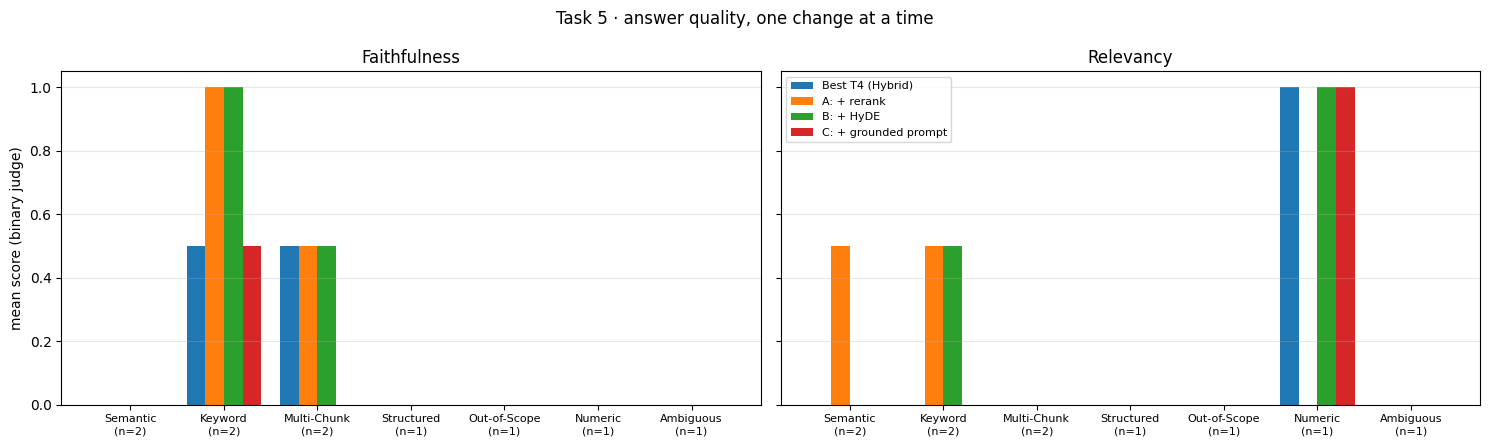

,category,retriever,question,expected,answer,refused,relevancy,faithfulness,pages
28,Out-of-Scope,Best T4 (Hybrid),How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,The provided text does not contain any specifi...,True,0.0,0.0,4
29,Out-of-Scope,A: + rerank,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,The provided text does not contain any specifi...,True,0.0,0.0,4
30,Out-of-Scope,B: + HyDE,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,The provided text does not contain any specifi...,True,0.0,0.0,4
31,Out-of-Scope,C: + grounded prompt,How much does a VYEPTI infusion cost?,Not in document. The report gives a phone numb...,The document does not provide this information.,True,0.0,0.0,4
32,Numeric,Best T4 (Hybrid),What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,About 30% of people with chronic migraine also...,False,1.0,0.0,6
33,Numeric,A: + rerank,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,About 30% of people with chronic migraine also...,False,0.0,0.0,6
34,Numeric,B: + HyDE,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,About 30% of people with chronic migraine also...,False,1.0,0.0,6
35,Numeric,C: + grounded prompt,What percentage of people with chronic migrain...,About 30 percent. The report also says over 55...,About 30% of people with chronic migraine also...,False,1.0,0.0,6
36,Ambiguous,Best T4 (Hybrid),"Both of my parents had migraines, so am I cert...",The report does not say. It does not discuss g...,"Based on the provided context, there's no dire...",False,0.0,0.0,"6,8,9"
37,Ambiguous,A: + rerank,"Both of my parents had migraines, so am I cert...",The report does not say. It does not discuss g...,"Based on the provided context, there's no dire...",False,0.0,0.0,"6,8,9"


Out-of-scope refusal rate (auto-flag; verify by hand):
 retriever
A: + rerank             1.0
B: + HyDE               1.0
Best T4 (Hybrid)        1.0
C: + grounded prompt    1.0
Name: refused, dtype: float64


In [ ]:
GROUNDED_QA = PromptTemplate(
    "You answer questions about a WebMD report on chronic migraine.\n"
    "Context (each passage starts with its page_label):\n---------------------\n{context_str}\n---------------------\n"
    "Rules:\n"
    "1. Use ONLY the context above. Never use outside knowledge.\n"
    "2. If the context does not contain the answer, say: \"The document does not provide this information.\" "
    "You may add one sentence about related information it does contain.\n"
    "3. Copy numbers, percentages and drug names exactly as written in the context.\n"
    "4. If the question assumes something the context does not support, say so rather than extrapolating.\n"
    "5. Finish with the page(s) you used, e.g. (p. 4).\n"
    "Question: {query_str}\nAnswer: ")

t5_suite = {f"Best T4 ({BEST_T4})": t5_retrievers[f"Best T4 ({BEST_T4})"],
            "A: + rerank": t5_retrievers["A: + rerank"], "B: + HyDE": t5_retrievers["B: + HyDE"]}
t5_engines = engines_from(t5_suite, list(t5_suite))
t5_engines["C: + grounded prompt"] = RetrieverQueryEngine.from_args(t5_suite[f"Best T4 ({BEST_T4})"], llm=llm, text_qa_template=GROUNDED_QA)
t5_ans = run_answer_eval(t5_engines, qdf, "t5_improvements")
display(summarize_answers(t5_ans)[0]); display(summarize_answers(t5_ans)[1])
plot_by_category(t5_ans, "Task 5 · answer quality, one change at a time", "t5_by_category.png")

# Manual refusal audit for the adversarial questions (the relevancy judge is unreliable here)
audit = manual_check_table(t5_ans)
display(audit)
oos = t5_ans[t5_ans.category == "Out-of-Scope"].groupby("retriever").refused.mean()
print("Out-of-scope refusal rate (auto-flag; verify by hand):\n", oos)